# Diagnostic-Driven Hybrid ML for ECG Classification

## Dataset
MIT-BIH Arrhythmia Database

## Research Framework
1. Data Diagnostics
2. Condition Mapping
3. Hybrid Strategy Selection
4. Model Training
5. Performance Evaluation

## Objective
To investigate whether a diagnostic-driven framework
for selecting hybrid machine learning strategies can
be applied to healthcare ECG data.

In [6]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt

import statsmodels
import wfdb
import neurokit2 as nk

from statsmodels.tsa.stattools import adfuller, kpss

print("Environment successfully initialized")
print("------------------------------")
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Statsmodels:", statsmodels.__version__)
print("WFDB:", wfdb.__version__)
print("NeuroKit2:", nk.__version__)

Environment successfully initialized
------------------------------
Python: 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:15:26) [Clang 20.1.8 ]
NumPy: 2.5.4
Pandas: 3.1.1
SciPy: 1.18.1
Statsmodels: 0.15.0
WFDB: 4.3.1
NeuroKit2: 0.3.0


In [8]:
from pathlib import Path

PROJECT_DIR = Path.cwd() / "ECG_Research"
DATA_DIR = PROJECT_DIR / "data" / "mitbih"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Folders created successfully!")

Project directory: /Users/hmdsahed/ECG Prof. Ozaydin/ECG_Research
Dataset directory: /Users/hmdsahed/ECG Prof. Ozaydin/ECG_Research/data/mitbih
Folders created successfully!


In [10]:
import wfdb

record = wfdb.rdrecord(
    "100",
    pn_dir="mitdb",
    physical=True
)

annotations = wfdb.rdann(
    "100",
    "atr",
    pn_dir="mitdb"
)

print("Recording downloaded successfully!")
print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)
print("Channels:", record.sig_name)
print("Annotations:", len(annotations.sample))

Recording downloaded successfully!
Signal shape: (650000, 2)
Sampling frequency: 360
Channels: ['MLII', 'V5']
Annotations: 2274


## 3. Initial ECG Data Loading

### 3.1 Loading the MIT-BIH Recording

The MIT-BIH Arrhythmia Database was accessed using the WFDB Python library. Recording 100 was selected for the initial data inspection.

The ECG signal and its corresponding expert annotations were successfully loaded.

### 3.2 Recording Information

The initial recording contains the following characteristics:

| Property | Value |
|---|---:|
| Recording ID | 100 |
| Total samples | 650,000 |
| Sampling frequency | 360 Hz |
| Number of channels | 2 |
| Channel 1 | MLII |
| Channel 2 | V5 |
| Number of annotations | 2,274 |
| Recording duration | Approximately 30.1 minutes |

### 3.3 Data Description

The recording contains two ECG channels:

- **MLII:** Modified Lead II ECG signal.
- **V5:** Precordial ECG signal.

The database also provides expert annotations that identify cardiac events at specific sample positions.

These annotations will be used to investigate heartbeat categories and define the classification targets.

### 3.4 Next Step

The next stage will involve:

1. Visual inspection of both ECG channels.
2. Examination of the expert annotation symbols.
3. Analysis of the annotation frequency and class distribution.
4. Selection of an appropriate ECG classification task.

These initial investigations will establish the data characteristics before applying the diagnostic-driven framework.

## 4. ECG Signal Visualization

### 4.1 Visual Inspection of ECG Signals

The first 10 seconds of the ECG recording will be visualized for both MLII and V5 channels.

The purpose of this step is to:

- Observe the general waveform morphology.
- Examine the amplitude and temporal patterns.
- Identify visible signal variations and potential noise.
- Compare the waveform characteristics between the two channels.

This visual inspection provides an initial understanding of the ECG signals before performing statistical and signal-level diagnostics.

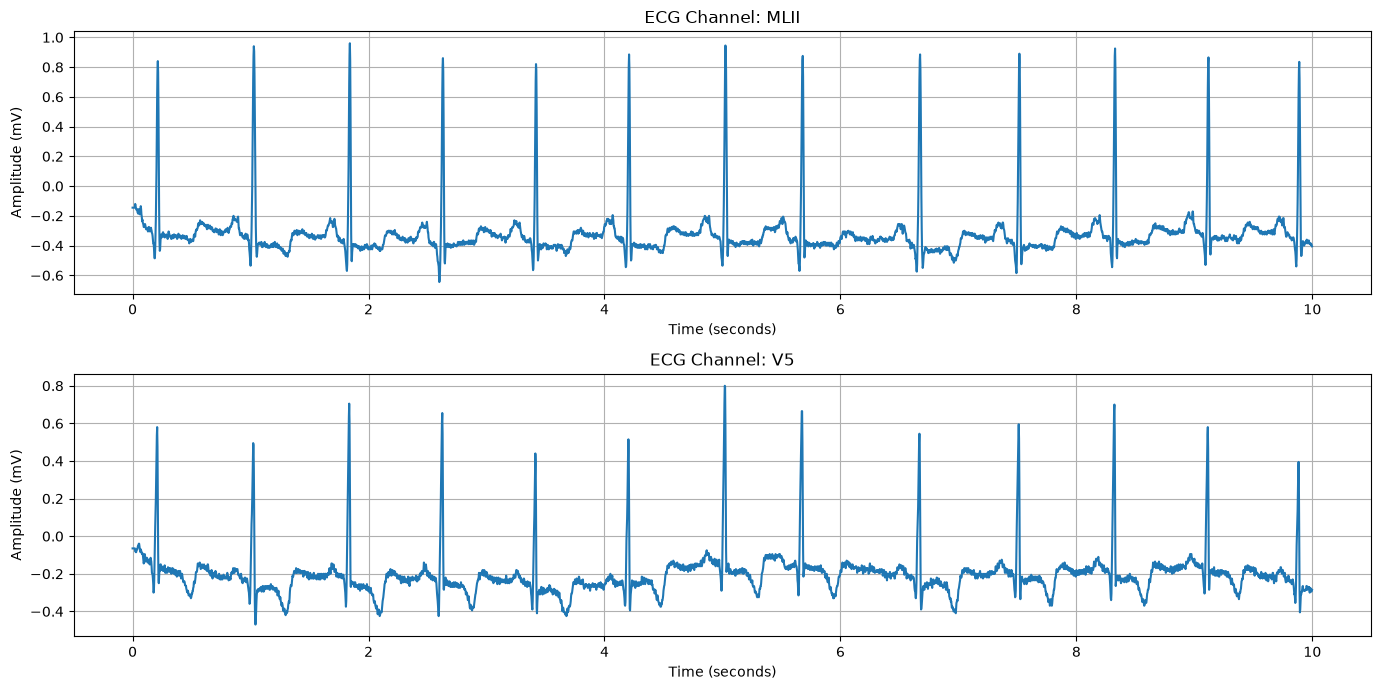

In [14]:
import numpy as np
import matplotlib.pyplot as plt

duration = 10
samples = int(duration * record.fs)

time = np.arange(samples) / record.fs

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

for i, channel in enumerate(record.sig_name):
    axes[i].plot(time, record.p_signal[:samples, i])
    axes[i].set_title(f"ECG Channel: {channel}")
    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Amplitude (mV)")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

### 4.3 Initial Observations

The visualization of the first 10 seconds of recording 100 shows identifiable and repeating ECG waveform patterns in both MLII and V5 channels.

The following observations were made:

- Both channels contain prominent peaks associated with cardiac activity.
- The waveform morphology differs between MLII and V5.
- Variations in signal amplitude and baseline are visible across the recording.
- The signals show temporal variations that require further statistical investigation.

These observations provide an initial understanding of the ECG signals. However, visual inspection alone is insufficient to determine stationarity, signal quality, or the presence of clinically abnormal heartbeats.

Further statistical and signal-level diagnostics will be conducted to investigate these characteristics.

In [17]:
import pandas as pd

annotation_df = pd.DataFrame({
    "sample": annotations.sample,
    "time_seconds": annotations.sample / record.fs,
    "symbol": annotations.symbol
})

print("First 15 annotations:")
display(annotation_df.head(15))

print("\nAnnotation symbol distribution:")
display(annotation_df["symbol"].value_counts().to_frame("count"))

First 15 annotations:


,sample,time_seconds,symbol
0,18,0.050000,+
1,77,0.213889,N
2,370,1.027778,N
3,662,1.838889,N
4,946,2.627778,N
5,1231,3.419444,N
6,1515,4.208333,N
7,1809,5.025000,N
8,2044,5.677778,A
9,2402,6.672222,N



Annotation symbol distribution:


,count
symbol,
N,2239
A,33
+,1
V,1


## 5. ECG Annotation Analysis

### 5.1 Expert Annotation Distribution

The expert annotations associated with MIT-BIH recording 100 were extracted and analysed to examine the distribution of annotated cardiac events.

The annotation distribution is as follows:

| Annotation | Count | Description |
|---|---:|---|
| N | 2,239 | Normal beat |
| A | 33 | Atrial premature beat |
| V | 1 | Premature ventricular contraction |
| + | 1 | Rhythm-change marker |

The `+` annotation represents a rhythm marker rather than a heartbeat category.

### 5.2 Initial Class Imbalance Observation

Considering the three heartbeat categories (N, A, and V), the recording contains:

- Normal beats: 2,239
- Abnormal beats (A and V): 34

This indicates a substantial imbalance between normal and abnormal heartbeat annotations.

The observed imbalance makes recording 100 a useful starting point for investigating class distribution and its implications for machine learning.

### 5.3 Implications for the Proposed Framework

Class imbalance will be considered an important data condition in the diagnostic stage.

Potential strategies, including class weighting and training-only resampling, will be investigated during model development.

However, the final classification scheme and imbalance-handling strategy will be determined after examining the annotation definitions and the complete dataset.

### 5.4 Next Step

The next stage will examine the annotation distribution quantitatively and determine an appropriate heartbeat classification scheme before constructing the machine learning dataset.

In [20]:
# Count heartbeat annotations only (exclude rhythm markers)
beat_df = annotation_df[
    annotation_df["symbol"].isin(["N", "A", "V"])
].copy()

class_counts = beat_df["symbol"].value_counts()

total_beats = class_counts.sum()
normal_count = class_counts["N"]
abnormal_count = class_counts.get("A", 0) + class_counts.get("V", 0)

imbalance_ratio = normal_count / abnormal_count

print("Total heartbeat annotations:", total_beats)
print("Normal beats:", normal_count)
print("Abnormal beats:", abnormal_count)
print("Imbalance ratio (Normal:Abnormal):", round(imbalance_ratio, 2))
print("Abnormal percentage:", round(abnormal_count / total_beats * 100, 2), "%")

Total heartbeat annotations: 2273
Normal beats: 2239
Abnormal beats: 34
Imbalance ratio (Normal:Abnormal): 65.85
Abnormal percentage: 1.5 %


### 5.5 Quantitative Assessment of Class Imbalance

The class distribution was further examined by grouping the heartbeat annotations into normal and abnormal categories.

The results for recording 100 are:

| Measurement | Result |
|---|---:|
| Total heartbeat annotations | 2,273 |
| Normal beats | 2,239 |
| Abnormal beats | 34 |
| Normal-to-abnormal ratio | 65.85:1 |
| Abnormal heartbeat percentage | 1.50% |

The results indicate a substantial class imbalance, with normal beats accounting for approximately 98.5% of the heartbeat annotations.

This finding identifies class imbalance as a potential challenge for ECG classification.

However, these results represent only one recording. Further analysis across the complete MIT-BIH database is required to determine the overall class distribution and assess whether the same imbalance pattern is present across different patients.

## 6. Complete MIT-BIH Dataset Analysis

### 6.1 Objective

The initial analysis examined only recording 100. To obtain a more representative understanding of the dataset, the next stage will investigate all available recordings in the MIT-BIH Arrhythmia Database.

### 6.2 Analysis Plan

The following information will be extracted from each recording:

- Recording identifier.
- Total number of expert annotations.
- Frequency of each annotation symbol.
- Distribution of heartbeat categories.
- Differences in annotation distributions across recordings.

### 6.3 Purpose

This analysis will help determine whether class imbalance is consistent across recordings or varies between patients.

The complete annotation distribution will also support the selection of an appropriate heartbeat classification task.

At this stage, all annotation symbols will be preserved. Non-beat annotations will be distinguished from heartbeat annotations before calculating the final class distribution.

In [28]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


In [30]:
from collections import Counter
from tqdm.auto import tqdm
import wfdb
import pandas as pd

# Get all MIT-BIH recording IDs
record_list = wfdb.get_record_list("mitdb")

print("Total recordings:", len(record_list))
print("Recording IDs:", record_list)

# Collect annotation information
all_annotations = []
recording_summary = []

for rec_id in tqdm(record_list, desc="Reading annotations"):

    ann = wfdb.rdann(
        rec_id,
        "atr",
        pn_dir="mitdb"
    )

    symbol_counts = Counter(ann.symbol)

    recording_summary.append({
        "record_id": rec_id,
        "total_annotations": len(ann.symbol),
        "unique_symbols": len(symbol_counts)
    })

    for symbol, count in symbol_counts.items():
        all_annotations.append({
            "record_id": rec_id,
            "symbol": symbol,
            "count": count
        })

# Convert results into DataFrames
recording_summary_df = pd.DataFrame(recording_summary)
all_annotations_df = pd.DataFrame(all_annotations)

# Overall annotation distribution
overall_distribution = (
    all_annotations_df
    .groupby("symbol")["count"]
    .sum()
    .sort_values(ascending=False)
    .to_frame("total_count")
)

print("\nRecording summary:")
display(recording_summary_df.head())

print("\nOverall annotation symbol distribution:")
display(overall_distribution)

print("\nTotal recordings processed:",
      len(recording_summary_df))

Total recordings: 48
Recording IDs: ['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']


Reading annotations:   0%|          | 0/48 [00:00<?, ?it/s]


Recording summary:


,record_id,total_annotations,unique_symbols
0,100,2274,4
1,101,1874,6
2,102,2192,5
3,103,2091,4
4,104,2311,7



Overall annotation symbol distribution:


,total_count
symbol,
N,75052
L,8075
R,7259
V,7130
/,7028
A,2546
+,1291
f,982
F,803



Total recordings processed: 48


## 6. Complete MIT-BIH Annotation Analysis

### 6.1 Dataset Coverage

The annotation analysis was extended to all 48 recordings in the MIT-BIH Arrhythmia Database.

All 48 recordings were successfully processed using the WFDB library.

For each recording, the analysis extracted:
- Recording identifier.
- Total number of annotations.
- Number of unique annotation symbols.
- Frequency of each annotation symbol.

### 6.2 Overall Annotation Distribution

The aggregated annotation distribution revealed several frequently occurring symbols.

| Symbol | Count |
|---|---:|
| N | 75,052 |
| L | 8,075 |
| R | 7,259 |
| V | 7,130 |
| / | 7,028 |
| A | 2,546 |
| + | 1,291 |
| f | 982 |
| F | 803 |
| ~ | 616 |
| ! | 472 |

Additional less frequent annotation symbols were also identified.

### 6.3 Initial Findings

The complete dataset contains a considerably more diverse annotation distribution than the initial examination of recording 100.

In particular, the presence of multiple heartbeat categories indicates that the classification problem may involve more than simply distinguishing normal and abnormal beats.

However, not all annotation symbols represent heartbeat classes. Therefore, annotation symbols must be grouped and interpreted according to their definitions before calculating the final class distribution.

### 6.4 Next Step

The next stage will identify the heartbeat-related annotation symbols and distinguish them from rhythm markers and other annotation types.

This will establish a reliable basis for calculating class imbalance and defining the classification task.

In [33]:
# Display all annotation symbols and their counts

symbol_summary = (
    all_annotations_df
    .groupby("symbol")["count"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

symbol_summary["percentage"] = (
    symbol_summary["count"] /
    symbol_summary["count"].sum() * 100
)

display(symbol_summary)

,symbol,count,percentage
0,N,75052,66.625831
1,L,8075,7.168411
2,R,7259,6.444024
3,V,7130,6.329507
4,/,7028,6.238959
5,A,2546,2.260158
6,+,1291,1.146058
7,f,982,0.871750
8,F,803,0.712846
9,~,616,0.546841


### 6.5 Heartbeat Annotation Classification

To establish a standardised classification scheme, the AAMI five-class heartbeat grouping will be investigated.

The original MIT-BIH annotation symbols will be mapped into five categories:

- N: Normal and related beats.
- S: Supraventricular ectopic beats.
- V: Ventricular ectopic beats.
- F: Fusion beats.
- Q: Paced and unclassifiable beats.

Non-beat annotations will be excluded from heartbeat classification.

The original annotation symbols will be preserved alongside their mapped categories to maintain traceability.

This classification scheme will provide a consistent basis for analysing class distribution and developing the subsequent machine learning models.

In [36]:
# AAMI five-class annotation mapping

aami_mapping = {
    "N": ["N", "L", "R", "e", "j"],
    "S": ["A", "a", "J", "S"],
    "V": ["V", "E"],
    "F": ["F"],
    "Q": ["/", "f", "Q"]
}

# Reverse mapping: original symbol -> AAMI class
symbol_to_aami = {
    symbol: aami_class
    for aami_class, symbols in aami_mapping.items()
    for symbol in symbols
}

# Calculate total counts for each AAMI class
aami_counts = {}

for aami_class, symbols in aami_mapping.items():
    aami_counts[aami_class] = (
        all_annotations_df[
            all_annotations_df["symbol"].isin(symbols)
        ]["count"].sum()
    )

aami_summary = pd.DataFrame({
    "AAMI_Class": list(aami_counts.keys()),
    "Total_Beats": list(aami_counts.values())
})

aami_summary["Percentage"] = (
    aami_summary["Total_Beats"] /
    aami_summary["Total_Beats"].sum() * 100
)

print("AAMI Five-Class Distribution:")
display(aami_summary)

print("Total classified beats:", aami_summary["Total_Beats"].sum())

print("\nUnmapped annotation symbols:")
unmapped = symbol_summary[
    ~symbol_summary["symbol"].isin(symbol_to_aami.keys())
]
display(unmapped)

AAMI Five-Class Distribution:


,AAMI_Class,Total_Beats,Percentage
0,N,90631,82.772572
1,S,2781,2.539865
2,V,7236,6.608581
3,F,803,0.733374
4,Q,8043,7.345608


Total classified beats: 109494

Unmapped annotation symbols:


,symbol,count,percentage
6,+,1291,1.146058
9,~,616,0.546841
10,!,472,0.419008
11,"""",437,0.387938
13,x,193,0.171332
15,|,132,0.117180
20,[,6,0.005326
21,],6,0.005326


### 6.6 AAMI Five-Class Heartbeat Distribution

The heartbeat annotations from all 48 MIT-BIH recordings were grouped into five AAMI categories.

The resulting distribution is presented below.

| AAMI Class | Total Beats | Percentage |
|---|---:|---:|
| N | 90,631 | 82.77% |
| S | 2,781 | 2.54% |
| V | 7,236 | 6.61% |
| F | 803 | 0.73% |
| Q | 8,043 | 7.35% |
| **Total** | **109,494** | **100.00%** |

A total of 3,153 annotations were excluded because they did not belong to the selected heartbeat classification categories.

### 6.7 Initial Class Distribution Findings

The results demonstrate substantial class imbalance across the five heartbeat categories.

The N class represents approximately 82.77% of classified heartbeat annotations, whereas the F class represents only 0.73%.

The S and F categories are particularly underrepresented compared with the dominant N category.

These findings identify class imbalance as an important condition for the subsequent diagnostic-driven framework.

However, the current analysis aggregates annotations across all recordings. It does not yet account for patient-independent data splitting or differences in class distribution between individual patients.

### 6.8 Next Step

The next stage will examine class imbalance quantitatively and investigate how the distribution varies across individual recordings.

The classification mapping and recording-level distributions will also be checked before constructing the final machine learning dataset.

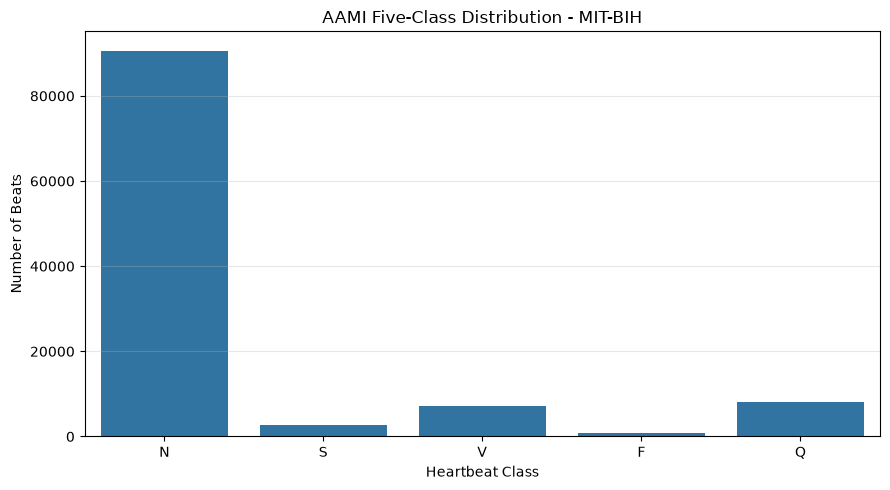

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=aami_summary,
    x="AAMI_Class",
    y="Total_Beats"
)

plt.title("AAMI Five-Class Distribution - MIT-BIH")
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Beats")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.9 Visualization of AAMI Class Distribution

The distribution of the five AAMI heartbeat categories was visualized using a bar chart.

The visualization highlights a substantial difference in the number of observations across classes.

The N category is the dominant class, containing 90,631 beats, while the F category is the least represented, containing 803 beats.

This distribution indicates that the classification task has a significant class imbalance problem.

The visualization provides preliminary evidence that class imbalance should be considered during the diagnostic stage and subsequent model development.

Further analysis will examine the imbalance quantitatively and investigate its variation across individual recordings.

In [42]:
# Calculate majority-to-minority class ratios

majority_count = aami_summary.loc[
    aami_summary["AAMI_Class"] == "N",
    "Total_Beats"
].iloc[0]

imbalance_results = []

for _, row in aami_summary.iterrows():

    class_name = row["AAMI_Class"]
    class_count = row["Total_Beats"]

    imbalance_results.append({
        "Class": class_name,
        "Count": class_count,
        "Percentage": row["Percentage"],
        "N_to_Class_Ratio": round(
            majority_count / class_count, 2
        )
    })

imbalance_df = pd.DataFrame(imbalance_results)

display(imbalance_df)

,Class,Count,Percentage,N_to_Class_Ratio
0,N,90631,82.772572,1.00
1,S,2781,2.539865,32.59
2,V,7236,6.608581,12.53
3,F,803,0.733374,112.87
4,Q,8043,7.345608,11.27


### 6.10 Quantitative Class Imbalance Assessment

The majority-to-minority class ratios were calculated using the N category as the reference class.

| Class | Count | Percentage | N-to-Class Ratio |
|---|---:|---:|---:|
| N | 90,631 | 82.77% | 1.00 |
| S | 2,781 | 2.54% | 32.59 |
| V | 7,236 | 6.61% | 12.53 |
| F | 803 | 0.73% | 112.87 |
| Q | 8,043 | 7.35% | 11.27 |

The results reveal substantial differences in class representation.

The F category has the highest imbalance ratio (112.87:1), followed by S (32.59:1), V (12.53:1), and Q (11.27:1).

These findings indicate that class imbalance varies considerably across heartbeat categories.

Therefore, the diagnostic-driven framework should consider not only the presence of class imbalance but also its severity and distribution across individual classes.

The current ratios are calculated from aggregated annotations and do not yet account for patient-level differences.

In [45]:
# Create recording-level AAMI class distribution

recording_aami = all_annotations_df.copy()

recording_aami["AAMI_Class"] = (
    recording_aami["symbol"].map(symbol_to_aami)
)

recording_aami = recording_aami.dropna(
    subset=["AAMI_Class"]
)

recording_class_counts = (
    recording_aami
    .pivot_table(
        index="record_id",
        columns="AAMI_Class",
        values="count",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

# Ensure all five classes exist
for cls in ["N", "S", "V", "F", "Q"]:
    if cls not in recording_class_counts.columns:
        recording_class_counts[cls] = 0

print("Recording-level AAMI distribution:")
display(recording_class_counts.head(15))

print("\nNumber of recordings containing each class:")

for cls in ["N", "S", "V", "F", "Q"]:
    present = (recording_class_counts[cls] > 0).sum()
    print(f"{cls}: {present}/48 recordings")

Recording-level AAMI distribution:


AAMI_Class,record_id,F,N,Q,S,V
0,100,0,2239,0,33,1
1,101,0,1860,2,3,0
2,102,0,99,2084,0,4
3,103,0,2082,0,2,0
4,104,0,163,2064,0,2
5,105,0,2526,5,0,41
6,106,0,1507,0,0,520
7,107,0,0,2078,0,59
8,108,2,1740,0,4,17
9,109,2,2492,0,0,38



Number of recordings containing each class:
N: 47/48 recordings
S: 32/48 recordings
V: 37/48 recordings
F: 17/48 recordings
Q: 9/48 recordings


### 6.11 Recording-Level Class Distribution

The AAMI heartbeat categories were examined separately across all 48 MIT-BIH recordings to investigate how class representation varies between recordings.

The number of recordings containing each category is shown below.

| Class | Recordings Containing Class | Coverage |
|---|---:|---:|
| N | 47/48 | 97.9% |
| S | 32/48 | 66.7% |
| V | 37/48 | 77.1% |
| F | 17/48 | 35.4% |
| Q | 9/48 | 18.8% |

### 6.12 Recording-Level Observations

The analysis reveals substantial variation in heartbeat category representation across recordings.

The N category is present in almost all recordings, whereas Q and F are concentrated in a smaller number of recordings.

For example, recording 102 contains 2,084 Q beats, while recording 100 contains none.

These findings indicate that class imbalance is accompanied by differences in class distribution across recordings.

### 6.13 Implications for Experimental Design

The observed recording-level differences are important when designing model validation.

A random heartbeat-level split may allow beats from the same recording to appear in both training and testing sets.

Therefore, patient-independent evaluation will be considered to assess model generalization to previously unseen recordings.

The distribution of minority classes across recordings will also be considered when designing the validation strategy.

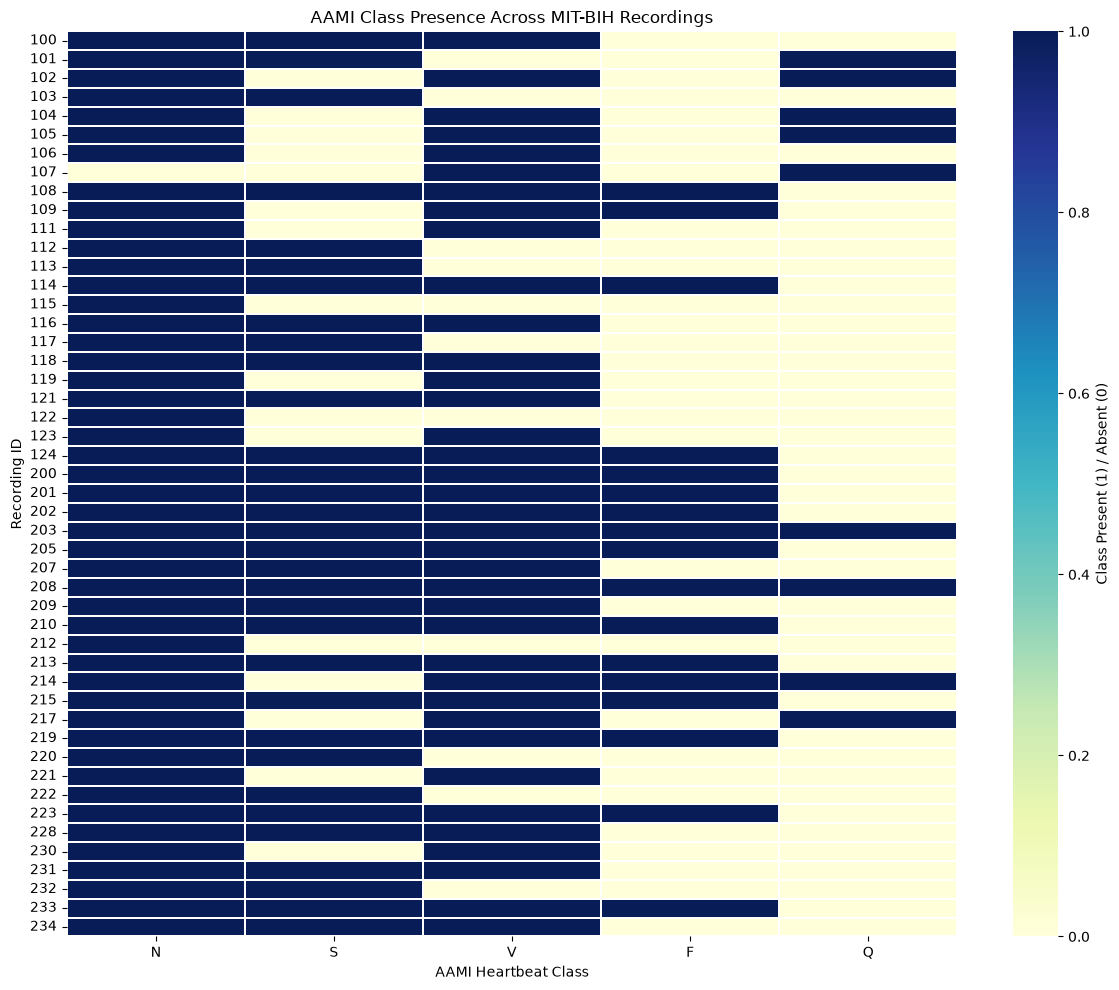

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare recording-level class presence
class_presence = recording_class_counts.set_index("record_id")[
    ["N", "S", "V", "F", "Q"]
]

# Convert counts into presence/absence
class_presence = (class_presence > 0).astype(int)

plt.figure(figsize=(12, 10))

sns.heatmap(
    class_presence,
    cmap="YlGnBu",
    linewidths=0.3,
    cbar_kws={"label": "Class Present (1) / Absent (0)"}
)

plt.title("AAMI Class Presence Across MIT-BIH Recordings")
plt.xlabel("AAMI Heartbeat Class")
plt.ylabel("Recording ID")

plt.tight_layout()
plt.show()

### 6.14 Visualization of Recording-Level Class Distribution

A binary heatmap was generated to visualize the presence or absence of the five AAMI heartbeat categories across the 48 MIT-BIH recordings.

Dark cells indicate that a heartbeat category is present in a recording, whereas light cells indicate its absence.

The visualization reveals differences in class coverage across recordings.

The N category is widely distributed, while F and Q are present in substantially fewer recordings.

These findings suggest that the dataset exhibits both class imbalance and recording-level heterogeneity in class representation.

This distinction is important for the subsequent experimental design because a model must be evaluated on recordings that were not used during training.

The heatmap represents class presence or absence rather than the frequency of individual heartbeat categories.

## 7. ECG Signal Diagnostics

### 7.1 Objective

This stage investigates the statistical characteristics of ECG signals using time-series diagnostic methods.

The objective is to identify signal properties that may influence preprocessing and machine learning strategy selection.

The initial analysis will use the MLII channel from MIT-BIH recording 100.

### 7.2 Diagnostic Methods

The following methods will be investigated:

1. **Augmented Dickey-Fuller (ADF) Test:** Examines the null hypothesis that the signal contains a unit root.
2. **KPSS Test:** Examines the null hypothesis that the signal is stationary around a constant level or deterministic trend, depending on the selected specification.
3. **Rolling Variance:** Examines how signal variability changes over time.

Both ADF and KPSS will be used because they have different null hypotheses and provide complementary evidence about stationarity.

### 7.3 Signal Representation

The original ECG signal is a continuous physiological time series containing repeated cardiac waveforms.

Stationarity tests will initially be applied to the raw MLII signal as an exploratory analysis. Their results will be interpreted carefully because periodic cardiac activity, baseline variation, and recording characteristics may affect the tests.

Further analysis may investigate derived representations, such as RR intervals and signal features.

### 7.4 Expected Outcome

This analysis will provide preliminary evidence about the stationarity and variance characteristics of the ECG signal.

The findings will later be considered alongside signal quality and class distribution when selecting suitable preprocessing and machine learning strategies.

In [56]:
# Extract the original MLII ECG signal

ecg_signal = record.p_signal[:, 0]

print("Signal channel:", record.sig_name[0])
print("Number of samples:", len(ecg_signal))
print("Sampling frequency:", record.fs)
print("Duration (seconds):", len(ecg_signal) / record.fs)
print("Mean amplitude:", np.mean(ecg_signal))
print("Standard deviation:", np.std(ecg_signal))
print("Minimum amplitude:", np.min(ecg_signal))
print("Maximum amplitude:", np.max(ecg_signal))

Signal channel: MLII
Number of samples: 650000
Sampling frequency: 360
Duration (seconds): 1805.5555555555557
Mean amplitude: -0.3062989769230769
Standard deviation: 0.19319954213721688
Minimum amplitude: -2.715
Maximum amplitude: 1.435


### 7.3 Stationarity Analysis Using ADF and KPSS

The Augmented Dickey-Fuller (ADF) and Kwiatkowski-Phillips-Schmidt-Shin (KPSS) tests will be applied to the original MLII ECG signal.

The ADF test uses the null hypothesis of a unit root, whereas the KPSS test uses the null hypothesis of stationarity.

Using both tests allows the stationarity characteristics to be examined from complementary statistical perspectives.

The significance level will be set to 0.05.

The test statistics, p-values, and corresponding interpretations will be recorded for further analysis.

In [59]:
from statsmodels.tsa.stattools import adfuller, kpss

# ADF test
adf_result = adfuller(ecg_signal)

# KPSS test
kpss_result = kpss(
    ecg_signal,
    regression="c",
    nlags="auto"
)

print("ADF TEST")
print("-------------------------")
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

print("\nKPSS TEST")
print("-------------------------")
print("KPSS Statistic:", kpss_result[0])
print("p-value:", kpss_result[1])

print("\nInterpretation at 0.05 significance level:")

if adf_result[1] < 0.05:
    print("ADF: Reject the unit-root null hypothesis.")
else:
    print("ADF: Fail to reject the unit-root null hypothesis.")

if kpss_result[1] < 0.05:
    print("KPSS: Reject the stationarity null hypothesis.")
else:
    print("KPSS: Fail to reject the stationarity null hypothesis.")

ADF TEST
-------------------------
ADF Statistic: -61.579436188234766
p-value: 0.0

KPSS TEST
-------------------------
KPSS Statistic: 3.845423543577324
p-value: 0.01

Interpretation at 0.05 significance level:
ADF: Reject the unit-root null hypothesis.
KPSS: Reject the stationarity null hypothesis.


/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/3518141412.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(ecg_signal)
/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/3518141412.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/3518141412.py:7: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 

### 7.4 ADF and KPSS Test Results

The ADF and KPSS tests were applied to the original MLII ECG signal from MIT-BIH recording 100.

The significance level was set to 0.05.

| Test | Test Statistic | p-value | Decision |
|---|---:|---:|---|
| ADF | -61.5794 | 0.0000 | Reject unit-root null hypothesis |
| KPSS | 3.8454 | 0.01 | Reject stationarity null hypothesis |

The ADF test rejects the unit-root null hypothesis, while the KPSS test rejects the null hypothesis of stationarity around a constant level.

The combination of these results does not support a straightforward stationary or conventional unit-root classification.

This finding indicates that additional investigation of the signal's statistical properties is necessary.

Potential factors include periodic cardiac activity, baseline variation, and time-varying signal characteristics.

The results are preliminary and are based on the original MLII recording. Further analysis using signal segments and derived features will be conducted before assigning a final stationarity condition.

### 7.6 Rolling Variance Analysis

Rolling variance is used to investigate changes in ECG signal variability over time.

For this experiment, the complete MLII signal from recording 100 will be analysed using a 10-second rolling window.

The analysis aims to:

- Examine temporal changes in signal variability.
- Identify periods of relatively high or low variance.
- Investigate whether signal variability remains consistent throughout the recording.

The rolling variance results will provide additional information about the statistical characteristics of the ECG signal and support subsequent diagnostic interpretation.

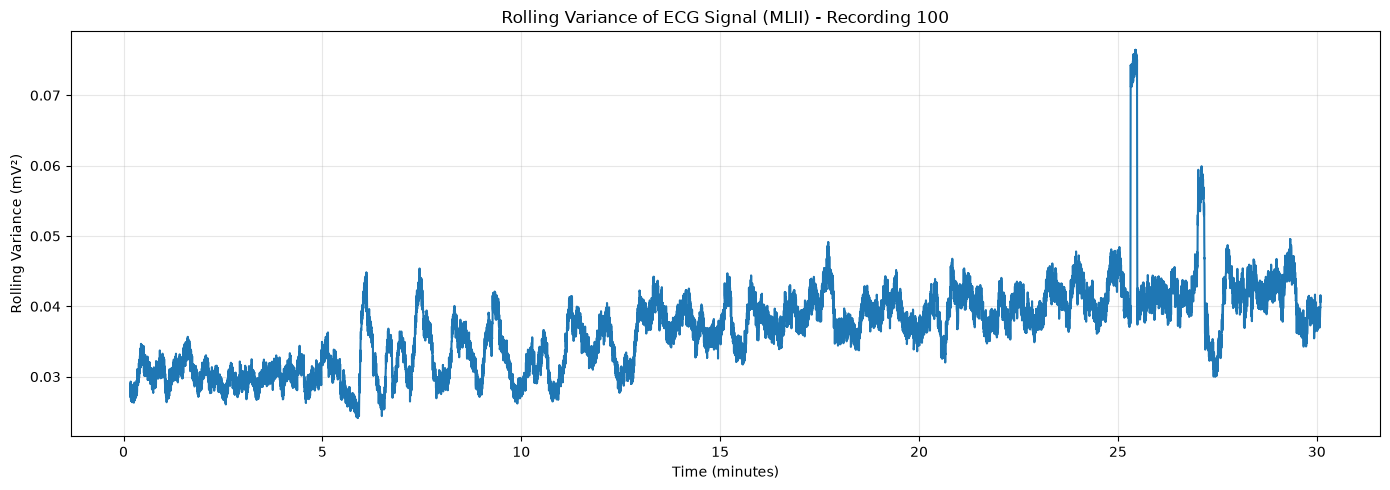

In [63]:
# Rolling variance analysis of the complete recording

window_size = 10 * record.fs  # 10-second window (3600 samples)

ecg_series = pd.Series(ecg_signal)

rolling_variance = ecg_series.rolling(
    window=window_size,
    min_periods=window_size
).var()

# Time axis in minutes
time_axis = np.arange(len(ecg_signal)) / record.fs / 60

# Plot rolling variance
plt.figure(figsize=(14, 5))

plt.plot(time_axis, rolling_variance)

plt.title("Rolling Variance of ECG Signal (MLII) - Recording 100")
plt.xlabel("Time (minutes)")
plt.ylabel("Rolling Variance (mV²)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [65]:
print("Rolling Variance Summary")
print("------------------------")
print("Mean:", rolling_variance.mean())
print("Median:", rolling_variance.median())
print("Standard deviation:", rolling_variance.std())
print("Minimum:", rolling_variance.min())
print("Maximum:", rolling_variance.max())

Rolling Variance Summary
------------------------
Mean: 0.036555582594188764
Median: 0.0368836618948911
Standard deviation: 0.005985080624568448
Minimum: 0.024117163700950787
Maximum: 0.07647175511522777


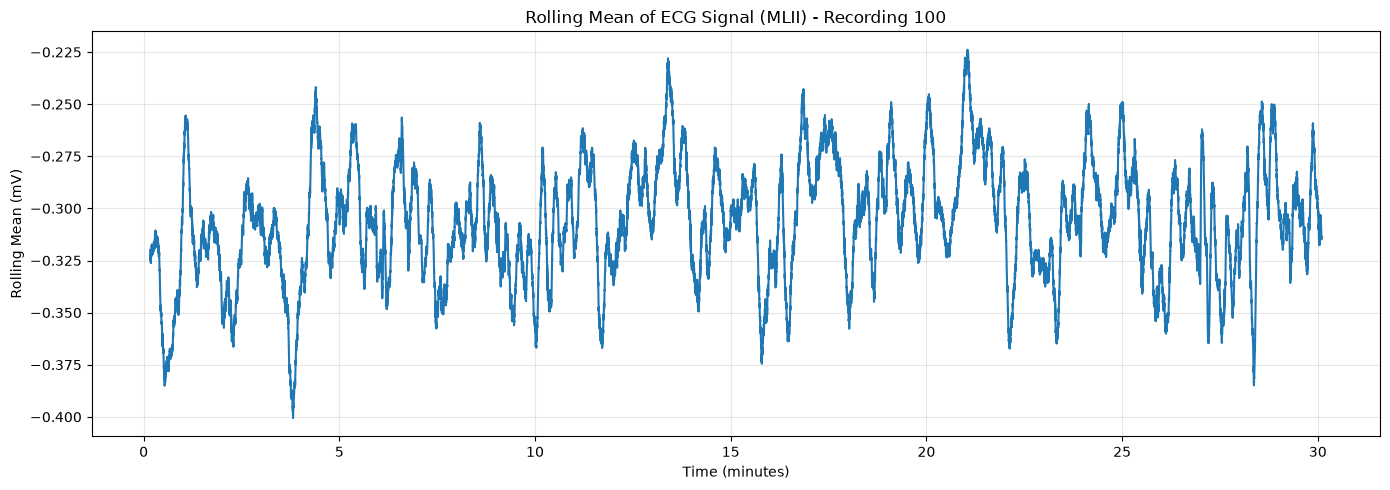

In [67]:
# Rolling mean analysis

rolling_mean = ecg_series.rolling(
    window=window_size,
    min_periods=window_size
).mean()

plt.figure(figsize=(14, 5))

plt.plot(time_axis, rolling_mean)

plt.title("Rolling Mean of ECG Signal (MLII) - Recording 100")
plt.xlabel("Time (minutes)")
plt.ylabel("Rolling Mean (mV)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 7.6.2 Numerical Summary of Rolling Variance

The numerical summary provides further evidence of temporal variation in the ECG signal.

The mean rolling variance was 0.03656 mV², while the median was 0.03688 mV². The standard deviation was 0.00599 mV². The minimum and maximum values were 0.02412 mV² and 0.07647 mV², respectively.

The maximum rolling variance was approximately 3.17 times the minimum. This indicates that some periods of the recording exhibit considerably greater signal variability than others.

Together with the rolling variance plot, these results suggest that signal variability changes over time. This finding will be considered alongside the ADF and KPSS tests in the overall diagnostic analysis.

### 7.7 Rolling Mean Analysis

Rolling mean analysis is used to examine changes in the average amplitude of the ECG signal over time.

The complete MLII signal from recording 100 will be analysed using a 10-second rolling window, consistent with the rolling variance analysis.

The objectives are to:
- Examine changes in the local average signal amplitude.
- Identify possible baseline shifts over time.
- Compare rolling mean patterns with the rolling variance results.

This analysis provides additional information about the temporal characteristics of the ECG signal.

### 7.7.1 Rolling Mean: Preliminary Observations

The rolling mean plot shows noticeable fluctuations in the local average amplitude of the ECG signal throughout recording 100.

The rolling mean does not remain at a constant level. Several upward and downward movements are visible across the recording, including a decrease to approximately −0.40 mV near 4 minutes and an increase to approximately −0.225 mV near 21 minutes.

No clear long-term upward or downward trend is observed. Instead, the plot indicates repeated local changes in the average signal level.

These observations suggest that the local mean of the ECG signal varies over time. The findings will be considered together with rolling variance and the ADF and KPSS test results.

In [72]:
print("Rolling Mean Summary")
print("--------------------")
print("Mean:", rolling_mean.mean())
print("Median:", rolling_mean.median())
print("Standard deviation:", rolling_mean.std())
print("Minimum:", rolling_mean.min())
print("Maximum:", rolling_mean.max())

Rolling Mean Summary
--------------------
Mean: -0.30623288230181844
Median: -0.30593472222222223
Standard deviation: 0.028119674595523326
Minimum: -0.4005902777777778
Maximum: -0.2238986111111111


### 7.7.2 Numerical Summary of Rolling Mean

The numerical summary shows that the mean of the rolling mean values is −0.30623 mV, while the median is −0.30593 mV. The standard deviation is 0.02812 mV.

The minimum and maximum rolling mean values are −0.40059 mV and −0.22390 mV, respectively. This range indicates that the local average amplitude changes across different sections of the recording.

The results support the visual observation that the ECG signal does not maintain a constant local mean throughout the recording. However, these findings should be interpreted alongside the stationarity tests and other signal diagnostics rather than used as independent evidence of nonstationarity.

In [75]:
diagnostic_summary = pd.DataFrame({
    "Diagnostic": [
        "ADF statistic",
        "ADF p-value",
        "KPSS statistic",
        "KPSS p-value",
        "Mean rolling variance",
        "Median rolling variance",
        "Std rolling variance",
        "Mean rolling mean",
        "Median rolling mean",
        "Std rolling mean"
    ],
    "Value": [
        adf_result[0],
        adf_result[1],
        kpss_result[0],
        kpss_result[1],
        rolling_variance.mean(),
        rolling_variance.median(),
        rolling_variance.std(),
        rolling_mean.mean(),
        rolling_mean.median(),
        rolling_mean.std()
    ]
})

diagnostic_summary

,Diagnostic,Value
0,ADF statistic,-61.579436
1,ADF p-value,0.000000
2,KPSS statistic,3.845424
3,KPSS p-value,0.010000
4,Mean rolling variance,0.036556
5,Median rolling variance,0.036884
6,Std rolling variance,0.005985
7,Mean rolling mean,-0.306233
8,Median rolling mean,-0.305935
9,Std rolling mean,0.028120


### 7.8 Consolidated Diagnostic Findings: Recording 100

The diagnostic analysis of MIT-BIH recording 100 combined the ADF test, KPSS test, rolling variance, and rolling mean.

The ADF test produced a statistic of −61.5794 with a p-value of approximately 0.0000, leading to rejection of the unit-root null hypothesis. In contrast, the KPSS test produced a statistic of 3.8454 with a reported p-value of 0.0100, leading to rejection of the null hypothesis of stationarity around a constant.

The rolling variance analysis showed temporal variation, with a mean of 0.03656 and a standard deviation of 0.00599. The rolling mean also fluctuated, with a mean of −0.30623 mV and a standard deviation of 0.02812 mV.

Overall, the two stationarity tests provide conflicting evidence, while the rolling statistics indicate changes in local signal characteristics over time. These findings suggest that a more detailed investigation across multiple ECG recordings is necessary before drawing conclusions about the stationarity properties of the MIT-BIH database.

At this stage, the results are preliminary and are limited to recording 100.

### 7.9 Stationarity Analysis Across All 48 Recordings

The previous analysis examined the complete ECG signal from recording 100. However, a single recording may not represent the statistical characteristics of the entire MIT-BIH Arrhythmia Database.

Therefore, this section extends the ADF and KPSS tests to all 48 recordings.

For each recording, the MLII channel will be extracted and analysed separately using the same test configurations:

- ADF test with its default settings.
- KPSS test with `regression="c"` and `nlags="auto"`.

The results will be collected in a single dataframe to examine the consistency of stationarity characteristics across recordings.

This analysis will help identify whether the statistical properties observed in recording 100 are common across the dataset or vary between recordings.

In [79]:
from statsmodels.tsa.stattools import adfuller, kpss
from tqdm.notebook import tqdm

record_ids = wfdb.get_record_list("mitdb")

stationarity_results = []

for record_id in tqdm(record_ids, desc="Analysing ECG recordings"):

    record_data = wfdb.rdrecord(
        record_id,
        pn_dir="mitdb",
        physical=True
    )

    # Extract MLII channel
    signal = record_data.p_signal[:, 0]

    # ADF test
    adf_result = adfuller(signal)

    # KPSS test
    kpss_result = kpss(
        signal,
        regression="c",
        nlags="auto"
    )

    stationarity_results.append({
        "record": record_id,
        "ADF_statistic": adf_result[0],
        "ADF_p_value": adf_result[1],
        "KPSS_statistic": kpss_result[0],
        "KPSS_p_value": kpss_result[1]
    })

stationarity_df = pd.DataFrame(stationarity_results)

stationarity_df

Analysing ECG recordings:   0%|          | 0/48 [00:00<?, ?it/s]

/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/1727356610.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(signal)
/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/1727356610.py:23: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/1727356610.py:23: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 o

,record,ADF_statistic,ADF_p_value,KPSS_statistic,KPSS_p_value
0,100,-61.579436,0.0,3.845424,0.010000
1,101,-36.275160,0.0,0.223014,0.100000
2,102,-72.365267,0.0,2.700239,0.010000
3,103,-37.036648,0.0,0.077364,0.100000
4,104,-68.667543,0.0,0.252366,0.100000
5,105,-57.732336,0.0,0.045563,0.100000
6,106,-64.253657,0.0,0.600652,0.022577
7,107,-71.213612,0.0,0.016352,0.100000
8,108,-25.711500,0.0,0.008662,0.100000
9,109,-82.555508,0.0,0.123771,0.100000


### 7.9 Stationarity Analysis Across All 48 MIT-BIH Recordings

The ADF and KPSS tests were applied to the complete MLII signal from all 48 recordings in the MIT-BIH Arrhythmia Database.

At a 5% significance level, the ADF test rejected the unit-root null hypothesis for all 48 recordings. The reported ADF p-values were 0.000000, indicating strong evidence against the presence of a unit root.

The KPSS test produced different results. For 19 recordings, the reported p-value was below 0.05, leading to rejection of the null hypothesis of stationarity around a constant. For the remaining 29 recordings, the null hypothesis was not rejected.

The results therefore indicate two patterns:

- In 29 recordings, both tests are consistent with stationarity.
- In 19 recordings, the tests provide conflicting evidence.

These findings suggest that the statistical characteristics of the raw ECG signals vary across recordings. Therefore, a single stationarity classification may not adequately describe the entire dataset.

The results should be interpreted cautiously because the KPSS test generated interpolation warnings for some recordings, and its reported p-values may be limited by the available lookup-table range. Furthermore, failure to reject the KPSS null hypothesis does not prove stationarity.

These findings are preliminary and will be considered alongside additional signal diagnostics before selecting appropriate modelling strategies.

In [82]:
alpha = 0.05

adf_rejections = (stationarity_df["ADF_p_value"] < alpha).sum()
kpss_rejections = (stationarity_df["KPSS_p_value"] < alpha).sum()

kpss_non_rejections = (
    stationarity_df["KPSS_p_value"] >= alpha
).sum()

print("STATIONARITY TEST SUMMARY")
print("-------------------------")
print("Total recordings:", len(stationarity_df))
print("ADF rejections:", adf_rejections)
print("KPSS rejections:", kpss_rejections)
print("KPSS non-rejections:", kpss_non_rejections)

STATIONARITY TEST SUMMARY
-------------------------
Total recordings: 48
ADF rejections: 48
KPSS rejections: 19
KPSS non-rejections: 29


In [84]:
# Identify recordings where KPSS rejects stationarity

kpss_rejected_records = stationarity_df[
    stationarity_df["KPSS_p_value"] < 0.05
]["record"].tolist()

print("Recordings with KPSS rejection:")
print(kpss_rejected_records)

print("\nNumber of recordings:", len(kpss_rejected_records))

Recordings with KPSS rejection:
['100', '102', '106', '112', '115', '117', '119', '122', '123', '200', '201', '205', '213', '215', '220', '221', '223', '231', '232']

Number of recordings: 19


In [86]:
# Identify recordings in each KPSS group

kpss_rejected = set(kpss_rejected_records)

rolling_variance_results = []

for record_id in tqdm(record_ids, desc="Calculating rolling variance"):

    record_data = wfdb.rdrecord(
        record_id,
        pn_dir="mitdb",
        physical=True
    )

    signal = record_data.p_signal[:, 0]

    # 10-second rolling window
    window_size = int(record_data.fs * 10)

    rolling_var = (
        pd.Series(signal)
        .rolling(window=window_size)
        .var()
        .dropna()
    )

    rolling_variance_results.append({
        "record": record_id,
        "KPSS_group": (
            "KPSS_rejected"
            if record_id in kpss_rejected
            else "KPSS_not_rejected"
        ),
        "mean_rolling_variance": rolling_var.mean(),
        "median_rolling_variance": rolling_var.median(),
        "std_rolling_variance": rolling_var.std(),
        "max_rolling_variance": rolling_var.max()
    })

rolling_variance_df = pd.DataFrame(rolling_variance_results)

rolling_variance_df.head()

Calculating rolling variance:   0%|          | 0/48 [00:00<?, ?it/s]

,record,KPSS_group,mean_rolling_variance,median_rolling_variance,std_rolling_variance,max_rolling_variance
0,100,KPSS_rejected,0.036556,0.036884,0.005985,0.076472
1,101,KPSS_not_rejected,0.066098,0.055639,0.062732,0.788614
2,102,KPSS_rejected,0.035371,0.035170,0.003238,0.052062
3,103,KPSS_not_rejected,0.099052,0.095531,0.043714,0.783677
4,104,KPSS_not_rejected,0.060853,0.054074,0.019598,0.219877


In [90]:
from pathlib import Path

project_path = Path.cwd()

notebook_path = project_path / "1st experiment.ipynb"

print("Project directory:", project_path)
print("Notebook exists:", notebook_path.exists())
print("Notebook path:", notebook_path)

Project directory: /Users/hmdsahed/ecg-diagnostic-driven-framework, Sahed HM, Ozaydin F
Notebook exists: True
Notebook path: /Users/hmdsahed/ecg-diagnostic-driven-framework, Sahed HM, Ozaydin F/1st experiment.ipynb


In [92]:
from pathlib import Path

print(repr(str(Path.cwd())))

'/Users/hmdsahed/ecg-diagnostic-driven-framework, Sahed HM, Ozaydin F'


In [94]:
# Compare rolling variance between KPSS groups

variance_group_summary = (
    rolling_variance_df
    .groupby("KPSS_group")[
        [
            "mean_rolling_variance",
            "median_rolling_variance",
            "std_rolling_variance",
            "max_rolling_variance"
        ]
    ]
    .agg(["mean", "median", "std"])
)

variance_group_summary

mean_rolling_variance                      \
                                   mean    median       std   
KPSS_group                                                    
KPSS_not_rejected              0.171604  0.120246  0.144923   
KPSS_rejected                  0.109175  0.081962  0.099659   

                  median_rolling_variance                      \
                                     mean    median       std   
KPSS_group                                                      
KPSS_not_rejected                0.153111  0.097630  0.144122   
KPSS_rejected                    0.106640  0.077083  0.099695   

                  std_rolling_variance                      \
                                  mean    median       std   
KPSS_group                                                   
KPSS_not_rejected             0.099487  0.076669  0.098996   
KPSS_rejected                 0.036184  0.027139  0.028856   

                  max_rolling_variance                      
                                  mean    median       std  
KPSS_group                                                  
KPSS_not_rejected             1.162751  0.966727  1.098176  
KPSS_rejected                 0.391351  0.303157  0.288350

In [96]:
# Count recordings in each group

rolling_variance_df["KPSS_group"].value_counts()

KPSS_group
KPSS_not_rejected    29
KPSS_rejected        19
Name: count, dtype: int64

In [98]:
from scipy.stats import mannwhitneyu

rejected = rolling_variance_df.loc[
    rolling_variance_df["KPSS_group"] == "KPSS_rejected",
    "mean_rolling_variance"
]

not_rejected = rolling_variance_df.loc[
    rolling_variance_df["KPSS_group"] == "KPSS_not_rejected",
    "mean_rolling_variance"
]

u_stat, p_value = mannwhitneyu(
    rejected,
    not_rejected,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", u_stat)
print("P-value:", p_value)
print("Rejected group median:", rejected.median())
print("Not rejected group median:", not_rejected.median())

Mann-Whitney U statistic: 185.0
P-value: 0.057774937027114184
Rejected group median: 0.08196219791956758
Not rejected group median: 0.12024645627554569


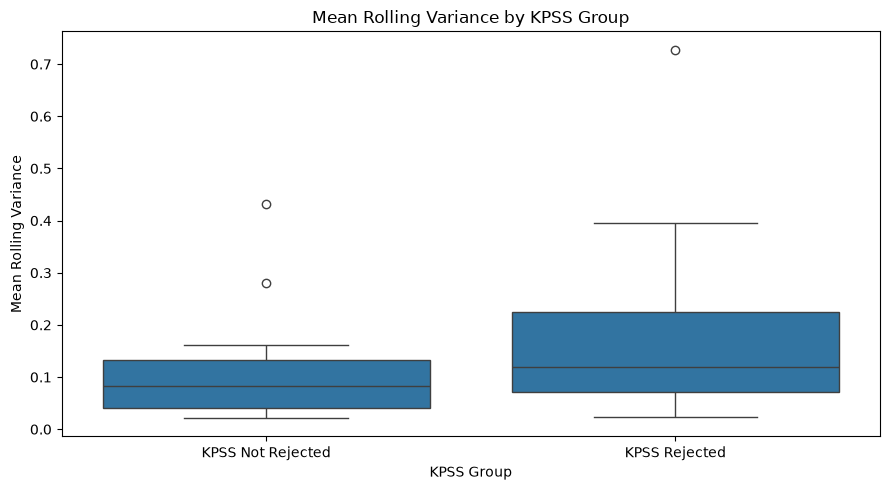

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=rolling_variance_df,
    x="KPSS_group",
    y="mean_rolling_variance"
)

plt.title("Mean Rolling Variance by KPSS Group")
plt.xlabel("KPSS Group")
plt.ylabel("Mean Rolling Variance")
plt.xticks(
    ticks=[0, 1],
    labels=["KPSS Not Rejected", "KPSS Rejected"]
)

plt.tight_layout()
plt.show()

In [102]:
rolling_variance_df.groupby("KPSS_group")[
    "mean_rolling_variance"
].median()

KPSS_group
KPSS_not_rejected    0.120246
KPSS_rejected        0.081962
Name: mean_rolling_variance, dtype: float64

In [104]:
print(
    rolling_variance_df.groupby("KPSS_group")[
        "mean_rolling_variance"
    ].describe()
)

                   count      mean       std       min       25%       50%  \
KPSS_group                                                                   
KPSS_not_rejected   29.0  0.171604  0.144923  0.024305  0.072309  0.120246   
KPSS_rejected       19.0  0.109175  0.099659  0.021402  0.041056  0.081962   

                        75%       max  
KPSS_group                             
KPSS_not_rejected  0.224090  0.727612  
KPSS_rejected      0.131855  0.431704  


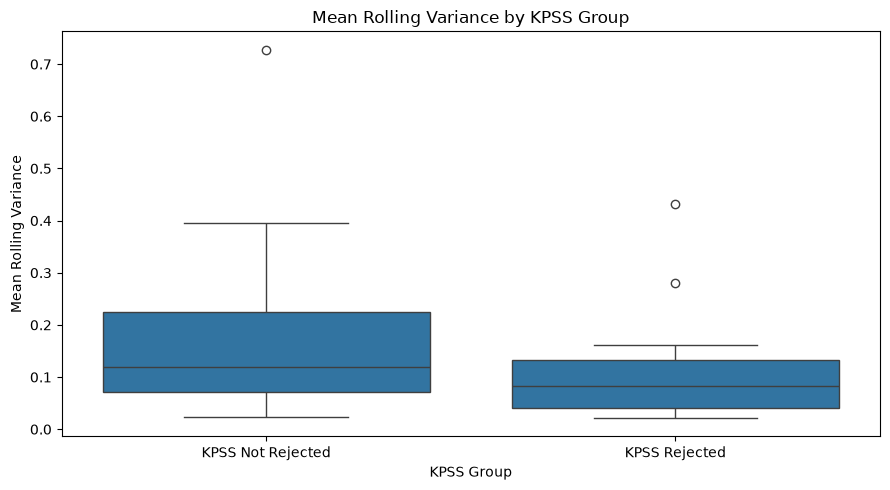

In [106]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=rolling_variance_df,
    x="KPSS_group",
    y="mean_rolling_variance",
    order=["KPSS_not_rejected", "KPSS_rejected"]
)

plt.title("Mean Rolling Variance by KPSS Group")
plt.xlabel("KPSS Group")
plt.ylabel("Mean Rolling Variance")

plt.xticks(
    [0, 1],
    ["KPSS Not Rejected", "KPSS Rejected"]
)

plt.tight_layout()
plt.show()

### 7.11 Comparative Analysis of Rolling Variance Across KPSS Groups

To investigate the relationship between stationarity-test outcomes and local signal variability, recording-level mean rolling variance was compared between the two KPSS groups.

The KPSS-not-rejected group (n = 29) showed a mean rolling variance of 0.171604 and a median of 0.120246. In comparison, the KPSS-rejected group (n = 19) showed a mean of 0.109175 and a median of 0.081962.

The Mann–Whitney U test was used to compare the distributions of recording-level mean rolling variance. The test produced a U statistic of 185.0 and a p-value of 0.057775. Therefore, the difference did not reach statistical significance at the 0.05 level.

Although the KPSS-rejected group exhibited lower descriptive mean and median rolling variance, these results do not establish a statistically significant association between rolling variance and KPSS outcomes.

These preliminary findings suggest that local variance alone may not sufficiently characterize the statistical behaviour of ECG recordings. Further investigation using complementary signal-level and time-series diagnostic features is warranted.

### 7.12 Rolling Mean Analysis Across All Recordings

This experiment examines local changes in the mean ECG signal across all 48 MIT-BIH recordings using a 10-second rolling window.

For each recording, the following statistics will be calculated:

- Mean of rolling mean
- Median of rolling mean
- Standard deviation of rolling mean
- Minimum rolling mean
- Maximum rolling mean

The resulting recording-level features will be compared between recordings that reject and do not reject the KPSS stationarity null hypothesis.

The objective is to investigate whether local mean behaviour provides additional diagnostic information beyond rolling variance.

In [110]:
from tqdm.notebook import tqdm
import pandas as pd
import wfdb

rolling_mean_results = []

for record_id in tqdm(record_ids, desc="Calculating rolling mean"):

    record_data = wfdb.rdrecord(
        record_id,
        pn_dir="mitdb",
        physical=True
    )

    signal = record_data.p_signal[:, 0]

    # 10-second rolling window
    window_size = int(record_data.fs * 10)

    rolling_mean = (
        pd.Series(signal)
        .rolling(window=window_size)
        .mean()
        .dropna()
    )

    rolling_mean_results.append({
        "record": record_id,
        "KPSS_group": (
            "KPSS_rejected"
            if record_id in kpss_rejected
            else "KPSS_not_rejected"
        ),
        "mean_rolling_mean": rolling_mean.mean(),
        "median_rolling_mean": rolling_mean.median(),
        "std_rolling_mean": rolling_mean.std(),
        "min_rolling_mean": rolling_mean.min(),
        "max_rolling_mean": rolling_mean.max()
    })

rolling_mean_df = pd.DataFrame(rolling_mean_results)

rolling_mean_df.head()

Calculating rolling mean:   0%|          | 0/48 [00:00<?, ?it/s]

,record,KPSS_group,mean_rolling_mean,median_rolling_mean,std_rolling_mean,min_rolling_mean,max_rolling_mean
0,100,KPSS_rejected,-0.306233,-0.305935,0.028120,-0.400590,-0.223899
1,101,KPSS_not_rejected,-0.284258,-0.286162,0.047468,-0.601856,-0.053817
2,102,KPSS_rejected,-0.245894,-0.244908,0.030586,-0.334467,-0.149646
3,103,KPSS_not_rejected,-0.231442,-0.232769,0.068183,-0.654664,0.390099
4,104,KPSS_not_rejected,-0.224977,-0.224619,0.043191,-0.389187,-0.092643


In [112]:
rolling_mean_summary = (
    rolling_mean_df
    .groupby("KPSS_group")[
        [
            "mean_rolling_mean",
            "median_rolling_mean",
            "std_rolling_mean",
            "min_rolling_mean",
            "max_rolling_mean"
        ]
    ]
    .agg(["mean", "median", "std"])
)

rolling_mean_summary

mean_rolling_mean                     median_rolling_mean  \
                               mean    median       std                mean   
KPSS_group                                                                    
KPSS_not_rejected         -0.289319 -0.169697  0.244592           -0.290451   
KPSS_rejected             -0.413758 -0.305355  0.287760           -0.415806   

                                      std_rolling_mean                      \
                     median       std             mean    median       std   
KPSS_group                                                                   
KPSS_not_rejected -0.169375  0.246011         0.081239  0.072656  0.037154   
KPSS_rejected     -0.304232  0.286813         0.062778  0.051960  0.028870   

                  min_rolling_mean                     max_rolling_mean  \
                              mean    median       std             mean   
KPSS_group                                                                
KPSS_not_rejected        -0.749854 -0.598010  0.513725         0.161606   
KPSS_rejected            -0.668546 -0.537128  0.364522        -0.161400   

                                       
                     median       std  
KPSS_group                             
KPSS_not_rejected  0.172418  0.219621  
KPSS_rejected     -0.091179  0.266953

### 7.13 Statistical Comparison of Rolling Mean Variability

The standard deviation of the rolling mean was selected to examine changes in local average ECG amplitude over time.

A Mann–Whitney U test will be used to compare this recording-level feature between the KPSS-rejected and KPSS-not-rejected groups.

The purpose is to investigate whether local mean variability provides additional information about the statistical characteristics of ECG recordings.

In [115]:
from scipy.stats import mannwhitneyu

rejected_mean_std = rolling_mean_df.loc[
    rolling_mean_df["KPSS_group"] == "KPSS_rejected",
    "std_rolling_mean"
]

not_rejected_mean_std = rolling_mean_df.loc[
    rolling_mean_df["KPSS_group"] == "KPSS_not_rejected",
    "std_rolling_mean"
]

u_stat, p_value = mannwhitneyu(
    rejected_mean_std,
    not_rejected_mean_std,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", u_stat)
print("P-value:", p_value)

print("KPSS rejected median:", rejected_mean_std.median())
print("KPSS not rejected median:", not_rejected_mean_std.median())

Mann-Whitney U statistic: 175.0
P-value: 0.03501160542427184
KPSS rejected median: 0.0519598229301992
KPSS not rejected median: 0.07265569922730007


### 7.13 Statistical Comparison of Rolling Mean Variability

The standard deviation of the rolling mean was compared between the KPSS-rejected and KPSS-not-rejected groups using the Mann–Whitney U test.

The KPSS-rejected group (n = 19) had a median rolling mean standard deviation of 0.05196, whereas the KPSS-not-rejected group (n = 29) had a median of 0.07266.

The Mann–Whitney U test produced a statistic of 175.0 and a p-value of 0.03501. This indicates a statistically significant difference between the two distributions at the 0.05 significance level.

The results suggest that recordings in the KPSS-rejected group exhibit lower variability in their local mean signal level.

In comparison with the rolling variance analysis, which did not show a statistically significant group difference (p = 0.05777), rolling mean variability showed a statistically significant difference.

These preliminary findings suggest that different signal-level diagnostic features may provide complementary information about ECG recording characteristics. Further investigation is required to determine their robustness and relevance to the proposed diagnostic-driven modelling framework.

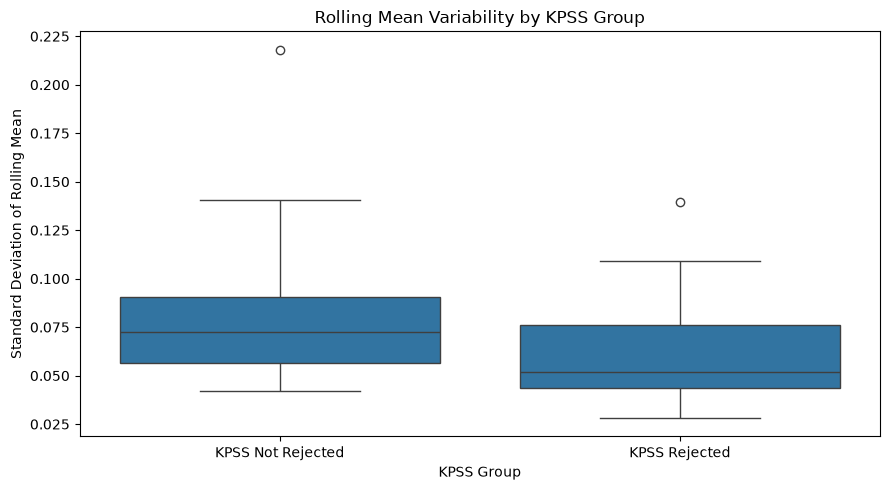

In [118]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=rolling_mean_df,
    x="KPSS_group",
    y="std_rolling_mean",
    order=["KPSS_not_rejected", "KPSS_rejected"]
)

plt.title("Rolling Mean Variability by KPSS Group")
plt.xlabel("KPSS Group")
plt.ylabel("Standard Deviation of Rolling Mean")

plt.xticks(
    [0, 1],
    ["KPSS Not Rejected", "KPSS Rejected"]
)

plt.tight_layout()
plt.show()

**Figure interpretation**

The boxplot shows that the KPSS-not-rejected group has a higher median standard deviation of rolling mean than the KPSS-rejected group. The former also exhibits a wider interquartile range, indicating greater variability across recordings.

This visual observation is consistent with the Mann–Whitney U test (U = 175.0, p = 0.03501), which identified a statistically significant difference between the two distributions at the 0.05 level.

The finding suggests that local mean variability may provide information about differences in ECG signal characteristics that is not captured by rolling variance alone. Further validation is required.

### 7.14 Consolidated Diagnostic Summary

This section consolidates the preliminary diagnostic findings obtained from the 48 MIT-BIH ECG recordings.

The analysis includes:
- ADF and KPSS stationarity test outcomes.
- Recording-level rolling variance characteristics.
- Recording-level rolling mean variability.
- Statistical comparisons between the two KPSS groups.

The purpose is to examine whether complementary signal diagnostics reveal differences in ECG recording characteristics that may inform the proposed diagnostic-driven framework.

In [122]:
diagnostic_summary = pd.DataFrame([
    {
        "Diagnostic": "ADF",
        "Result": "48/48 rejected unit-root null",
        "Statistic": "48 recordings",
        "P_value": "All < 0.05"
    },
    {
        "Diagnostic": "KPSS",
        "Result": "19 rejected; 29 not rejected",
        "Statistic": "48 recordings",
        "P_value": "19 < 0.05"
    },
    {
        "Diagnostic": "Mean rolling variance",
        "Result": "Lower median in KPSS-rejected group",
        "Statistic": 185.0,
        "P_value": 0.057775
    },
    {
        "Diagnostic": "SD of rolling mean",
        "Result": "Lower median in KPSS-rejected group",
        "Statistic": 175.0,
        "P_value": 0.035012
    }
])

diagnostic_summary

,Diagnostic,Result,Statistic,P_value
0,ADF,48/48 rejected unit-root null,48 recordings,All < 0.05
1,KPSS,19 rejected; 29 not rejected,48 recordings,19 < 0.05
2,Mean rolling variance,Lower median in KPSS-rejected group,185.0,0.057775
3,SD of rolling mean,Lower median in KPSS-rejected group,175.0,0.035012


/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/3863852744.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Not Rejected", "Rejected"])
/var/folders/pz/491clj2544j3428t496szrmh0000gn/T/ipykernel_80560/3863852744.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Not Rejected", "Rejected"])


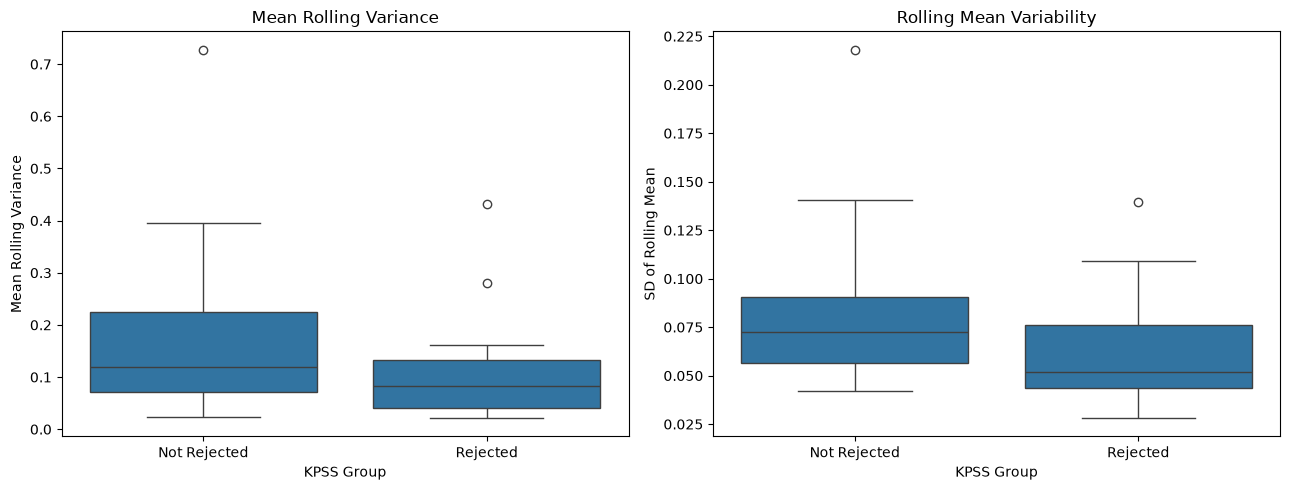

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=rolling_variance_df,
    x="KPSS_group",
    y="mean_rolling_variance",
    order=["KPSS_not_rejected", "KPSS_rejected"],
    ax=axes[0]
)

axes[0].set_title("Mean Rolling Variance")
axes[0].set_xlabel("KPSS Group")
axes[0].set_ylabel("Mean Rolling Variance")
axes[0].set_xticklabels(["Not Rejected", "Rejected"])

sns.boxplot(
    data=rolling_mean_df,
    x="KPSS_group",
    y="std_rolling_mean",
    order=["KPSS_not_rejected", "KPSS_rejected"],
    ax=axes[1]
)

axes[1].set_title("Rolling Mean Variability")
axes[1].set_xlabel("KPSS Group")
axes[1].set_ylabel("SD of Rolling Mean")
axes[1].set_xticklabels(["Not Rejected", "Rejected"])

plt.tight_layout()
plt.show()

### 7.15 Integration of Recording-Level Diagnostic Features

The recording-level diagnostic features are combined into a single dataset to provide a unified representation of ECG signal characteristics.

The integrated dataset includes ADF and KPSS test results, rolling variance statistics, and rolling mean statistics.

Each row represents one MIT-BIH recording. This dataset will serve as the basis for subsequent diagnostic comparisons and the investigation of relationships between signal characteristics and modelling strategies.

In [131]:
stationarity_df["KPSS_group"] = stationarity_df[
    "KPSS_p_value"
].apply(
    lambda p: "KPSS_rejected" if p < 0.05
    else "KPSS_not_rejected"
)

stationarity_df["KPSS_group"].value_counts()

KPSS_group
KPSS_not_rejected    29
KPSS_rejected        19
Name: count, dtype: int64

In [133]:
diagnostic_features_df = (
    stationarity_df
    .merge(
        rolling_variance_df.drop(columns=["KPSS_group"]),
        on="record",
        validate="one_to_one"
    )
    .merge(
        rolling_mean_df.drop(columns=["KPSS_group"]),
        on="record",
        validate="one_to_one"
    )
)

print("Dataset shape:", diagnostic_features_df.shape)
print("Number of recordings:", diagnostic_features_df["record"].nunique())

diagnostic_features_df.head()

Dataset shape: (48, 15)
Number of recordings: 48


,record,ADF_statistic,ADF_p_value,KPSS_statistic,KPSS_p_value,KPSS_group,mean_rolling_variance,median_rolling_variance,std_rolling_variance,max_rolling_variance,mean_rolling_mean,median_rolling_mean,std_rolling_mean,min_rolling_mean,max_rolling_mean
0,100,-61.579436,0.0,3.845424,0.01,KPSS_rejected,0.036556,0.036884,0.005985,0.076472,-0.306233,-0.305935,0.028120,-0.400590,-0.223899
1,101,-36.275160,0.0,0.223014,0.10,KPSS_not_rejected,0.066098,0.055639,0.062732,0.788614,-0.284258,-0.286162,0.047468,-0.601856,-0.053817
2,102,-72.365267,0.0,2.700239,0.01,KPSS_rejected,0.035371,0.035170,0.003238,0.052062,-0.245894,-0.244908,0.030586,-0.334467,-0.149646
3,103,-37.036648,0.0,0.077364,0.10,KPSS_not_rejected,0.099052,0.095531,0.043714,0.783677,-0.231442,-0.232769,0.068183,-0.654664,0.390099
4,104,-68.667543,0.0,0.252366,0.10,KPSS_not_rejected,0.060853,0.054074,0.019598,0.219877,-0.224977,-0.224619,0.043191,-0.389187,-0.092643


In [135]:
print("Dataset shape:", diagnostic_features_df.shape)

print("\nUnique recordings:",
      diagnostic_features_df["record"].nunique())

print("\nMissing values:")
print(diagnostic_features_df.isnull().sum())

print("\nKPSS group distribution:")
print(diagnostic_features_df["KPSS_group"].value_counts())

print("\nDuplicate recordings:",
      diagnostic_features_df["record"].duplicated().sum())

Dataset shape: (48, 15)

Unique recordings: 48

Missing values:
record                     0
ADF_statistic              0
ADF_p_value                0
KPSS_statistic             0
KPSS_p_value               0
KPSS_group                 0
mean_rolling_variance      0
median_rolling_variance    0
std_rolling_variance       0
max_rolling_variance       0
mean_rolling_mean          0
median_rolling_mean        0
std_rolling_mean           0
min_rolling_mean           0
max_rolling_mean           0
dtype: int64

KPSS group distribution:
KPSS_group
KPSS_not_rejected    29
KPSS_rejected        19
Name: count, dtype: int64

Duplicate recordings: 0


### 7.16 Validation of the Integrated Diagnostic Dataset

The recording-level diagnostic features were successfully integrated into a single dataset containing 48 rows and 15 columns.

Dataset validation confirmed:

- 48 unique ECG recordings.
- No duplicate recording identifiers.
- No missing values across the integrated features.
- 29 recordings in the KPSS-not-rejected group.
- 19 recordings in the KPSS-rejected group.

The integrated dataset contains ADF and KPSS statistics, KPSS group assignments, rolling variance features, and rolling mean features.

This dataset provides a consolidated basis for subsequent diagnostic analysis. These results remain exploratory and are specific to the selected MIT-BIH recordings and diagnostic settings.

8 
## 1. Loading the Integrated Diagnostic Dataset

### Objective

The objective of this section is to load the integrated diagnostic feature dataset generated during the previous analysis.

The dataset contains statistical features extracted from 48 selected MIT-BIH ECG recordings. These features include stationarity statistics (ADF and KPSS) and rolling statistical measurements (rolling variance and rolling mean).

The integrated dataset provides the foundation for investigating relationships among the extracted diagnostic features.

The dataset is loaded from a CSV file to avoid repeating the computationally expensive calculations performed during the previous stage.

We first verify the dataset dimensions, inspect the available features, and check for missing values.

In [3]:
import pandas as pd

diagnostic_features_df = pd.read_csv(
    "mitbih_integrated_diagnostic_features.csv"
)

print("Shape:", diagnostic_features_df.shape)
print(diagnostic_features_df.head())
print("\nMissing values:",
      diagnostic_features_df.isnull().sum().sum())

Shape: (48, 15)
   record  ADF_statistic  ADF_p_value  KPSS_statistic  KPSS_p_value  \
0     100     -61.579436          0.0        3.845424          0.01   
1     101     -36.275160          0.0        0.223014          0.10   
2     102     -72.365267          0.0        2.700239          0.01   
3     103     -37.036648          0.0        0.077364          0.10   
4     104     -68.667543          0.0        0.252366          0.10   

          KPSS_group  mean_rolling_variance  median_rolling_variance  \
0      KPSS_rejected               0.036556                 0.036884   
1  KPSS_not_rejected               0.066098                 0.055639   
2      KPSS_rejected               0.035371                 0.035170   
3  KPSS_not_rejected               0.099052                 0.095531   
4  KPSS_not_rejected               0.060853                 0.054074   

   std_rolling_variance  max_rolling_variance  mean_rolling_mean  \
0              0.005985              0.076472          -

### Results and Interpretation

The integrated diagnostic dataset contains 48 ECG recordings and 15 columns.

No missing values were detected in the dataset.

The dataset includes ADF and KPSS stationarity statistics, KPSS diagnostic groups, and rolling statistical features.

Since the dataset was successfully recovered from the previously saved CSV file, repeating the earlier statistical calculations was unnecessary.

Therefore, this dataset was used directly for the subsequent exploratory analysis.

In [5]:
diagnostic_features_df.to_csv(
    "mitbih_integrated_diagnostic_features_backup.csv",
    index=False
)

In [7]:

import pandas as pd
import numpy as np
from scipy.stats import spearmanr

# Select numerical diagnostic features
numeric_features = diagnostic_features_df.select_dtypes(
    include="number"
).drop(columns=["record"])

# Calculate Spearman correlation matrix
spearman_corr = numeric_features.corr(
    method="spearman"
)

# Display results
print("Spearman Correlation Matrix:")
display(spearman_corr.round(3))


Spearman Correlation Matrix:


,ADF_statistic,ADF_p_value,KPSS_statistic,KPSS_p_value,mean_rolling_variance,median_rolling_variance,std_rolling_variance,max_rolling_variance,mean_rolling_mean,median_rolling_mean,std_rolling_mean,min_rolling_mean,max_rolling_mean
ADF_statistic,1.000,NaN,-0.293,0.311,-0.309,-0.352,0.182,0.291,-0.061,-0.065,0.398,-0.300,0.364
ADF_p_value,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
KPSS_statistic,-0.293,NaN,1.000,-0.907,-0.305,-0.233,-0.593,-0.610,-0.073,-0.131,-0.284,0.171,-0.515
KPSS_p_value,0.311,NaN,-0.907,1.000,0.249,0.175,0.571,0.591,0.158,0.210,0.264,-0.083,0.580
mean_rolling_variance,-0.309,NaN,-0.305,0.249,1.000,0.980,0.631,0.525,-0.168,-0.136,0.505,-0.405,0.241
median_rolling_variance,-0.352,NaN,-0.233,0.175,0.980,1.000,0.518,0.422,-0.157,-0.129,0.465,-0.356,0.188
std_rolling_variance,0.182,NaN,-0.593,0.571,0.631,0.518,1.000,0.931,-0.186,-0.128,0.561,-0.534,0.488
max_rolling_variance,0.291,NaN,-0.610,0.591,0.525,0.422,0.931,1.000,-0.187,-0.127,0.620,-0.611,0.563
mean_rolling_mean,-0.061,NaN,-0.073,0.158,-0.168,-0.157,-0.186,-0.187,1.000,0.980,-0.228,0.725,0.480
median_rolling_mean,-0.065,NaN,-0.131,0.210,-0.136,-0.129,-0.128,-0.127,0.980,1.000,-0.240,0.688,0.497


## 2. Spearman Correlation Analysis

### Objective

The objective of this analysis is to investigate the relationships between the extracted diagnostic features.

Spearman rank correlation was selected to measure the strength and direction of monotonic relationships between pairs of numerical features.

Unlike Pearson correlation, Spearman correlation does not require the variables to follow a normal distribution.

This analysis helps identify:

1. Relationships between stationarity statistics and rolling features.
2. Associations between rolling variance and rolling mean characteristics.
3. Potential redundancy among the extracted diagnostic features.

The correlation coefficient (ρ) ranges from -1 to +1.

A positive coefficient indicates a positive association, while a negative coefficient indicates an inverse association.

A coefficient close to zero indicates a weak monotonic relationship.

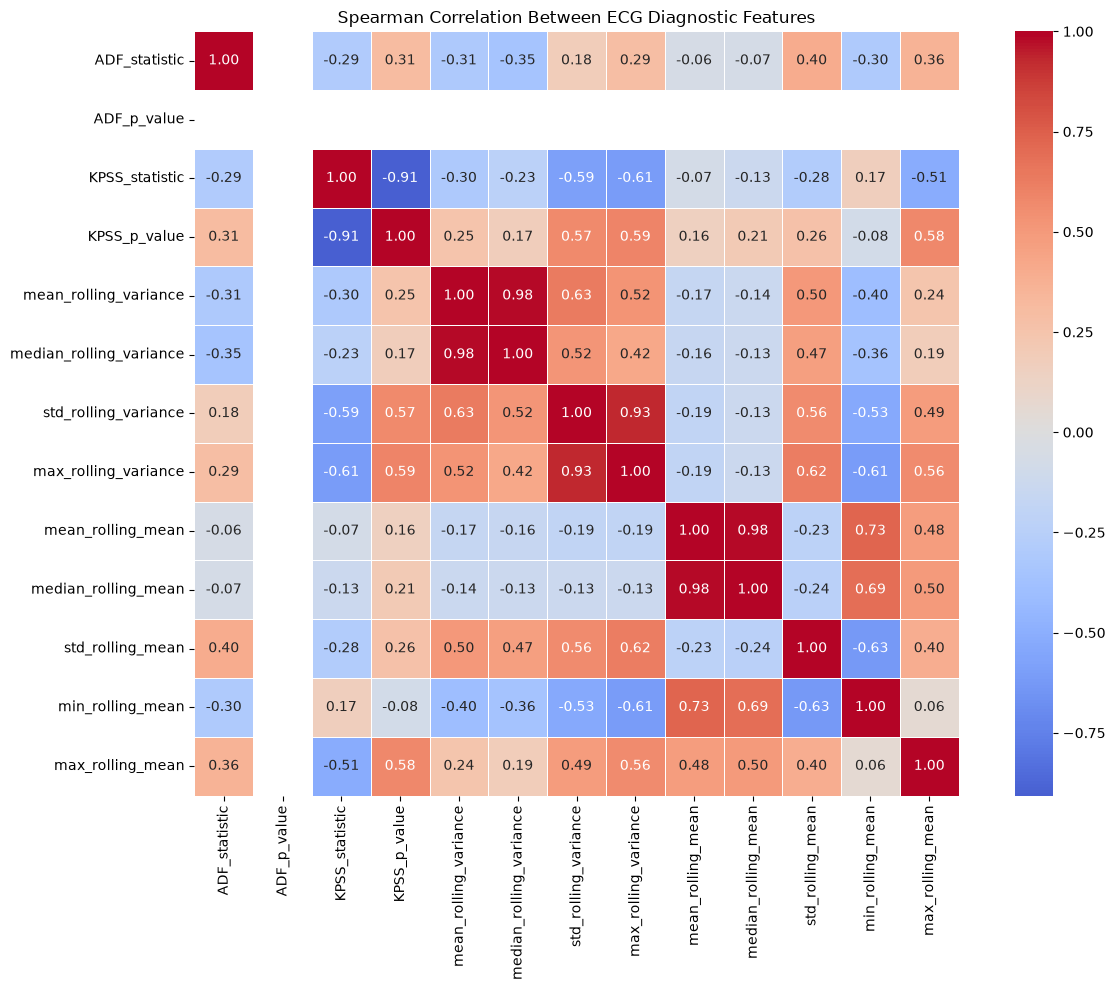

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(13, 10))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)

plt.title(
    "Spearman Correlation Between ECG Diagnostic Features"
)
plt.tight_layout()
plt.show()


### Results and Interpretation

The Spearman correlation analysis revealed several strong relationships among the diagnostic features.

The mean and median rolling variance showed an extremely strong positive correlation (ρ = 0.9800).

Similarly, the mean and median rolling mean were highly correlated (ρ = 0.9796).

The standard deviation and maximum rolling variance also showed a strong positive association (ρ = 0.9314).

These findings suggest that some rolling statistical features may capture overlapping information.

An inverse association was also observed between the KPSS statistic and KPSS p-value (ρ = -0.9066). This relationship is expected because both values originate from the same statistical test.

Further statistical testing was performed to determine which observed associations remained significant after multiple-testing correction.
## 3. Visualization of Feature Correlations

### Objective

A correlation heatmap was generated to provide a visual representation of the relationships among the diagnostic features.

The heatmap uses a color gradient to represent the direction and strength of the Spearman correlation coefficients.

Positive correlations are represented by warmer colors, while negative correlations are represented by cooler colors.

This visualization makes it easier to identify groups of strongly associated features and potential redundancy within the diagnostic feature set.

In [11]:

import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
from itertools import combinations

# Exclude constant ADF p-value column
features = diagnostic_features_df.select_dtypes(
    include="number"
).drop(columns=["record", "ADF_p_value"], errors="ignore")

# Remove any other constant columns
features = features.loc[
    :, features.nunique() > 1
]

# Calculate pairwise Spearman correlations
results = []

for col1, col2 in combinations(features.columns, 2):

    rho, p_value = spearmanr(
        features[col1],
        features[col2]
    )

    results.append({
        "Feature_1": col1,
        "Feature_2": col2,
        "Spearman_rho": rho,
        "p_value": p_value
    })

correlation_results_df = pd.DataFrame(results)

# Benjamini-Hochberg correction
reject, adjusted_p, _, _ = multipletests(
    correlation_results_df["p_value"],
    method="fdr_bh",
    alpha=0.05
)

correlation_results_df["adjusted_p_value"] = adjusted_p
correlation_results_df["significant_FDR"] = reject

# Sort by absolute correlation strength
correlation_results_df["abs_rho"] = (
    correlation_results_df["Spearman_rho"].abs()
)

correlation_results_df = correlation_results_df.sort_values(
    "abs_rho",
    ascending=False
)

display(
    correlation_results_df.drop(columns="abs_rho").round(4)
)

print(
    "\nSignificant associations after FDR correction:",
    reject.sum(),
    "out of",
    len(reject)
)


,Feature_1,Feature_2,Spearman_rho,p_value,adjusted_p_value,significant_FDR
30,mean_rolling_variance,median_rolling_variance,0.9800,0.0000,0.0000,True
56,mean_rolling_mean,median_rolling_mean,0.9796,0.0000,0.0000,True
45,std_rolling_variance,max_rolling_variance,0.9314,0.0000,0.0000,True
11,KPSS_statistic,KPSS_p_value,-0.9066,0.0000,0.0000,True
58,mean_rolling_mean,min_rolling_mean,0.7255,0.0000,0.0000,True
...,...,...,...,...,...,...
28,KPSS_p_value,min_rolling_mean,-0.0828,0.5758,0.6130,False
16,KPSS_statistic,mean_rolling_mean,-0.0726,0.6238,0.6535,False
7,ADF_statistic,median_rolling_mean,-0.0655,0.6585,0.6790,False
6,ADF_statistic,mean_rolling_mean,-0.0608,0.6815,0.6920,False



Significant associations after FDR correction: 33 out of 66


## 6. Identification of Highly Correlated Features

### Objective

The objective of this section is to identify highly correlated pairs of diagnostic features that may contain overlapping statistical information.

An absolute Spearman correlation threshold of 0.85 was selected for exploratory screening.

Feature pairs satisfying the following condition were identified:

|ρ| ≥ 0.85

This threshold was used to highlight strong associations that may indicate potential feature redundancy.

The analysis does not automatically remove any features. Instead, it provides an initial assessment of relationships that may need further investigation before downstream machine-learning experiments.

In [13]:
# Identify highly correlated feature pairs

threshold = 0.85

upper_triangle = spearman_corr.where(
    np.triu(
        np.ones(spearman_corr.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Spearman_rho"
]

high_corr_pairs["abs_rho"] = (
    high_corr_pairs["Spearman_rho"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["abs_rho"] >= threshold
].sort_values(
    "abs_rho",
    ascending=False
)

display(high_corr_pairs.round(4))

print(
    "\nNumber of highly correlated pairs:",
    len(high_corr_pairs)
)

,Feature_1,Feature_2,Spearman_rho,abs_rho
57,mean_rolling_variance,median_rolling_variance,0.9800,0.9800
113,mean_rolling_mean,median_rolling_mean,0.9796,0.9796
85,std_rolling_variance,max_rolling_variance,0.9314,0.9314
29,KPSS_statistic,KPSS_p_value,-0.9066,0.9066



Number of highly correlated pairs: 4


## 8. Comparison of Rolling Statistical Features Between KPSS Groups

### 8.1 Objective

The objective of this section is to investigate whether ECG recordings with different KPSS stationarity outcomes exhibit different rolling statistical characteristics.

Based on the KPSS test results obtained during the previous analysis, the recordings were divided into two diagnostic groups:

1. KPSS_rejected: Recordings for which the KPSS null hypothesis of stationarity was rejected.
2. KPSS_not_rejected: Recordings for which the KPSS null hypothesis was not rejected.

The analysis focuses on comparing rolling variance and rolling mean features between these two groups.

### Research Question

Do ECG recordings with different KPSS stationarity outcomes exhibit statistically distinguishable rolling variance and rolling mean characteristics?

### Statistical Approach

The Mann–Whitney U test will be used to compare the distributions of the rolling statistical features between the two independent groups.

This non-parametric test is appropriate for comparing two independent groups without requiring normally distributed observations.

The analysis will also calculate effect sizes to estimate the magnitude and direction of the observed differences.

Finally, multiple-testing correction will be applied to account for the multiple feature comparisons.

In [24]:
# Count recordings in each KPSS diagnostic group

group_counts = diagnostic_features_df[
    "KPSS_group"
].value_counts()

print("KPSS diagnostic group distribution:")
display(group_counts.to_frame(name="Number_of_recordings"))

print("\nTotal recordings:", group_counts.sum())

KPSS diagnostic group distribution:


,Number_of_recordings
KPSS_group,
KPSS_not_rejected,29
KPSS_rejected,19



Total recordings: 48


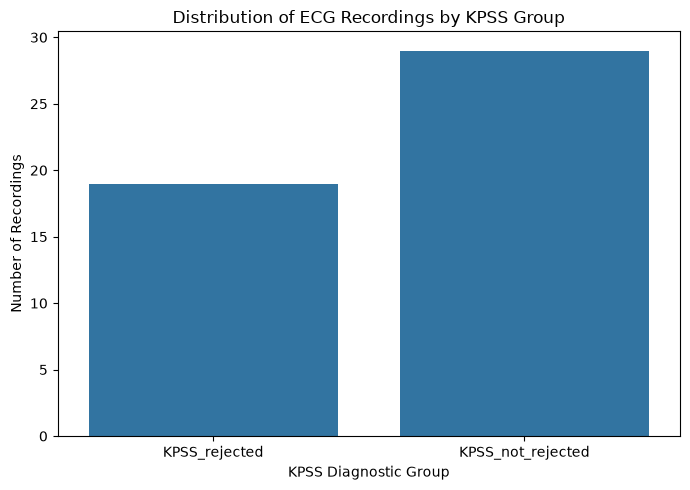

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=diagnostic_features_df,
    x="KPSS_group",
    order=["KPSS_rejected", "KPSS_not_rejected"]
)

plt.title("Distribution of ECG Recordings by KPSS Group")
plt.xlabel("KPSS Diagnostic Group")
plt.ylabel("Number of Recordings")

plt.tight_layout()
plt.show()

### 8.4 Selection of Rolling Statistical Features

The group comparison focuses on the rolling variance and rolling mean features extracted during the previous analysis.

The selected features are:

**Rolling variance features**

- mean_rolling_variance
- median_rolling_variance
- std_rolling_variance
- max_rolling_variance

**Rolling mean features**

- mean_rolling_mean
- median_rolling_mean
- std_rolling_mean
- min_rolling_mean
- max_rolling_mean

These nine features describe different aspects of the temporal behaviour of the ECG recordings.

The ADF and KPSS statistics are excluded from this comparison because the purpose of this analysis is to investigate whether the rolling signal characteristics differ between the two KPSS diagnostic groups.

In [29]:
# Define rolling statistical features

rolling_features = [
    "mean_rolling_variance",
    "median_rolling_variance",
    "std_rolling_variance",
    "max_rolling_variance",
    "mean_rolling_mean",
    "median_rolling_mean",
    "std_rolling_mean",
    "min_rolling_mean",
    "max_rolling_mean"
]

# Verify feature availability
print("Selected rolling features:")

for feature in rolling_features:
    print(feature)

print("\nNumber of selected features:", len(rolling_features))

Selected rolling features:
mean_rolling_variance
median_rolling_variance
std_rolling_variance
max_rolling_variance
mean_rolling_mean
median_rolling_mean
std_rolling_mean
min_rolling_mean
max_rolling_mean

Number of selected features: 9


In [31]:
# Calculate descriptive statistics for each KPSS group

descriptive_results = []

for feature in rolling_features:

    for group in ["KPSS_rejected", "KPSS_not_rejected"]:

        values = diagnostic_features_df.loc[
            diagnostic_features_df["KPSS_group"] == group,
            feature
        ].dropna()

        descriptive_results.append({
            "Feature": feature,
            "KPSS_group": group,
            "N": len(values),
            "Mean": values.mean(),
            "SD": values.std(),
            "Median": values.median(),
            "Q1": values.quantile(0.25),
            "Q3": values.quantile(0.75)
        })

descriptive_results_df = pd.DataFrame(descriptive_results)

display(descriptive_results_df.round(4))

,Feature,KPSS_group,N,Mean,SD,Median,Q1,Q3
0,mean_rolling_variance,KPSS_rejected,19,0.1092,0.0997,0.0820,0.0411,0.1319
1,mean_rolling_variance,KPSS_not_rejected,29,0.1716,0.1449,0.1202,0.0723,0.2241
2,median_rolling_variance,KPSS_rejected,19,0.1066,0.0997,0.0771,0.0365,0.1316
3,median_rolling_variance,KPSS_not_rejected,29,0.1531,0.1441,0.0976,0.0606,0.2027
4,std_rolling_variance,KPSS_rejected,19,0.0362,0.0289,0.0271,0.0147,0.0533
5,std_rolling_variance,KPSS_not_rejected,29,0.0995,0.0990,0.0767,0.0437,0.1210
6,max_rolling_variance,KPSS_rejected,19,0.3914,0.2883,0.3032,0.1514,0.5750
7,max_rolling_variance,KPSS_not_rejected,29,1.1628,1.0982,0.9667,0.5654,1.3975
8,mean_rolling_mean,KPSS_rejected,19,-0.4138,0.2878,-0.3054,-0.6683,-0.1619
9,mean_rolling_mean,KPSS_not_rejected,29,-0.2893,0.2446,-0.1697,-0.2314,-0.1610


### Interpretation of Descriptive Statistics

The descriptive analysis revealed differences in rolling statistical features between the two KPSS groups.

All four rolling variance features (mean, median, standard deviation, and maximum) showed higher median values in the KPSS_not_rejected group. The largest differences were observed in the standard deviation and maximum rolling variance, suggesting greater temporal variability in local variance among these recordings.

For rolling mean features, the KPSS_rejected group showed more negative median values for the mean and median rolling mean. In contrast, the KPSS_not_rejected group had a higher standard deviation of rolling mean and a positive median maximum rolling mean.

These observations suggest that the two KPSS groups may have different rolling statistical characteristics. However, descriptive statistics alone cannot establish whether these differences are statistically significant. Therefore, Mann–Whitney U tests will be used in the next step.

### 8.6 Mann–Whitney U Test

The descriptive statistics showed differences in rolling features between the two KPSS groups.

In this step, we use the Mann–Whitney U test to examine whether these differences are statistically significant.

We use this non-parametric test because it does not require the data to follow a normal distribution.

- H0: The distributions of a feature are the same between the two KPSS groups.
- H1: The distributions of a feature differ between the two KPSS groups.

We use a two-sided test with a significance level of 0.05.

In [35]:
from scipy.stats import mannwhitneyu

mannwhitney_results = []

for feature in rolling_features:
    group1 = diagnostic_features_df.loc[
        diagnostic_features_df["KPSS_group"] == "KPSS_rejected",
        feature
    ].dropna()

    group2 = diagnostic_features_df.loc[
        diagnostic_features_df["KPSS_group"] == "KPSS_not_rejected",
        feature
    ].dropna()

    u_statistic, p_value = mannwhitneyu(
        group1,
        group2,
        alternative="two-sided",
        method="auto"
    )

    mannwhitney_results.append({
        "Feature": feature,
        "U_statistic": u_statistic,
        "p_value": p_value
    })

mannwhitney_results_df = pd.DataFrame(mannwhitney_results)

display(mannwhitney_results_df.round(5))

,Feature,U_statistic,p_value
0,mean_rolling_variance,185.0,0.05777
1,median_rolling_variance,206.0,0.14576
2,std_rolling_variance,103.0,0.00029
3,max_rolling_variance,88.0,0.00008
4,mean_rolling_mean,215.0,0.20589
5,median_rolling_mean,195.0,0.09168
6,std_rolling_mean,175.0,0.03501
7,min_rolling_mean,312.0,0.44788
8,max_rolling_mean,92.0,0.00011


### Interpretation of Mann–Whitney U Test

The Mann–Whitney U test identified four rolling statistical features with p-values below 0.05:

- Standard deviation of rolling variance (p = 0.00029)
- Maximum rolling variance (p = 0.00008)
- Standard deviation of rolling mean (p = 0.03501)
- Maximum rolling mean (p = 0.00011)

The remaining five features did not show statistically significant differences at the 0.05 significance level.

These results provide preliminary evidence that some aspects of local ECG variability differ between the two KPSS groups. However, the p-values have not yet been adjusted for multiple comparisons.

### 8.7 Effect Size: Rank-Biserial Correlation

To measure the magnitude and direction of differences between the two KPSS groups, we calculate the rank-biserial correlation for each feature.

Unlike the p-value, the effect size helps us understand how strongly the two groups differ.

The rank-biserial correlation is calculated as:

\[
r_{rb} = \frac{2U}{n_1n_2}-1
\]

Where:

- \(U\) is the Mann–Whitney U statistic.
- \(n_1\) is the number of observations in the KPSS_rejected group.
- \(n_2\) is the number of observations in the KPSS_not_rejected group.

Positive values indicate that the KPSS_rejected group tends to have higher values, while negative values indicate the opposite.

In [39]:
effect_sizes = []

for feature in rolling_features:

    group1 = diagnostic_features_df.loc[
        diagnostic_features_df["KPSS_group"] == "KPSS_rejected",
        feature
    ].dropna()

    group2 = diagnostic_features_df.loc[
        diagnostic_features_df["KPSS_group"] == "KPSS_not_rejected",
        feature
    ].dropna()

    u_statistic, _ = mannwhitneyu(
        group1,
        group2,
        alternative="two-sided",
        method="auto"
    )

    rank_biserial = (
        (2 * u_statistic) / (len(group1) * len(group2))
    ) - 1

    effect_sizes.append(rank_biserial)

mannwhitney_results_df["Rank_biserial"] = effect_sizes

display(mannwhitney_results_df.round(5))

,Feature,U_statistic,p_value,Rank_biserial
0,mean_rolling_variance,185.0,0.05777,-0.32849
1,median_rolling_variance,206.0,0.14576,-0.25227
2,std_rolling_variance,103.0,0.00029,-0.62613
3,max_rolling_variance,88.0,0.00008,-0.68058
4,mean_rolling_mean,215.0,0.20589,-0.21960
5,median_rolling_mean,195.0,0.09168,-0.29220
6,std_rolling_mean,175.0,0.03501,-0.36479
7,min_rolling_mean,312.0,0.44788,0.13249
8,max_rolling_mean,92.0,0.00011,-0.66606


### Interpretation of Effect Sizes

The rank-biserial correlation analysis showed that the largest group differences occurred in maximum rolling variance (-0.681), maximum rolling mean (-0.666), and standard deviation of rolling variance (-0.626).

The negative effect sizes indicate that the KPSS_not_rejected group tends to have higher values for these features.

The standard deviation of rolling mean also showed a moderate difference (-0.365). In contrast, minimum rolling mean showed a small positive effect size (0.132), indicating a slight tendency toward higher values in the KPSS_rejected group.

Overall, the effect sizes suggest that differences between the KPSS groups are particularly noticeable in features describing the variability and extremes of rolling statistics.

### 8.8 Multiple-Testing Correction Using Benjamini–Hochberg FDR

Nine Mann–Whitney U tests were performed to compare rolling statistical features between the two KPSS groups.

Conducting multiple statistical tests increases the risk of false-positive findings. Therefore, we apply the Benjamini–Hochberg procedure to adjust the p-values.

The adjusted p-values will be used to determine which features remain statistically significant.

The significance threshold is set to 0.05.

In [43]:
from statsmodels.stats.multitest import multipletests

reject, adjusted_p_values, _, _ = multipletests(
    mannwhitney_results_df["p_value"],
    alpha=0.05,
    method="fdr_bh"
)

mannwhitney_results_df["adjusted_p_value"] = adjusted_p_values
mannwhitney_results_df["significant_FDR"] = reject

display(
    mannwhitney_results_df.sort_values(
        "adjusted_p_value"
    ).round(5)
)

print(
    "\nSignificant features after BH-FDR correction:",
    reject.sum(),
    "out of",
    len(reject)
)

,Feature,U_statistic,p_value,Rank_biserial,adjusted_p_value,significant_FDR
3,max_rolling_variance,88.0,0.00008,-0.68058,0.00051,True
8,max_rolling_mean,92.0,0.00011,-0.66606,0.00051,True
2,std_rolling_variance,103.0,0.00029,-0.62613,0.00086,True
6,std_rolling_mean,175.0,0.03501,-0.36479,0.07878,False
0,mean_rolling_variance,185.0,0.05777,-0.32849,0.10399,False
5,median_rolling_mean,195.0,0.09168,-0.29220,0.13753,False
1,median_rolling_variance,206.0,0.14576,-0.25227,0.18740,False
4,mean_rolling_mean,215.0,0.20589,-0.21960,0.23163,False
7,min_rolling_mean,312.0,0.44788,0.13249,0.44788,False



Significant features after BH-FDR correction: 3 out of 9


### Interpretation of Benjamini–Hochberg FDR Correction

After applying the Benjamini–Hochberg procedure to the nine Mann–Whitney U tests, three features remained statistically significant at an FDR threshold of 0.05:

1. Maximum rolling variance (adjusted p = 0.00051)
2. Maximum rolling mean (adjusted p = 0.00051)
3. Standard deviation of rolling variance (adjusted p = 0.00086)

All three features showed negative rank-biserial correlations, indicating that the KPSS_not_rejected group tended to have higher values.

The standard deviation of rolling mean was significant before correction (p = 0.03501), but did not remain significant after correction (adjusted p = 0.07878).

These findings suggest that maximum rolling values and the variability of rolling variance are particularly useful features for distinguishing the two KPSS groups in this dataset.

The results should be interpreted as exploratory recording-level findings. They do not establish causation or prove that these features can classify new ECG recordings.

### 8.9 Boxplot Visualization of Significant Features

In this step, we visualize the three features that remained statistically significant after Benjamini–Hochberg FDR correction:
1. Maximum rolling variance
2. Maximum rolling mean
3. Standard deviation of rolling variance

Boxplots are used to compare the distributions of these features between the KPSS_rejected and KPSS_not_rejected groups.

This visualization provides a graphical view of the group differences identified by the statistical tests.

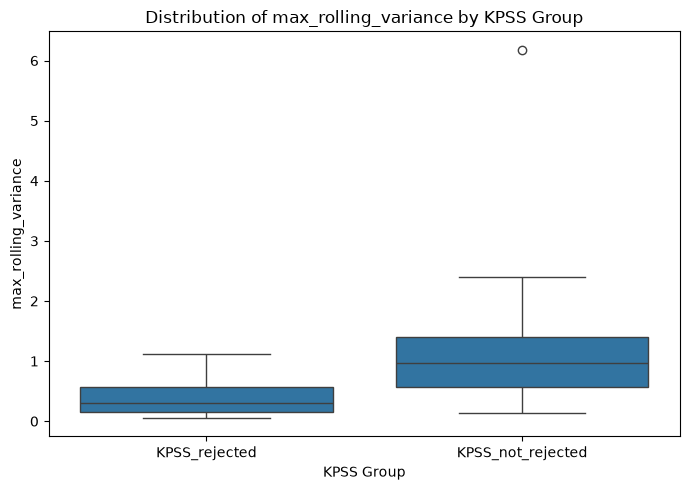

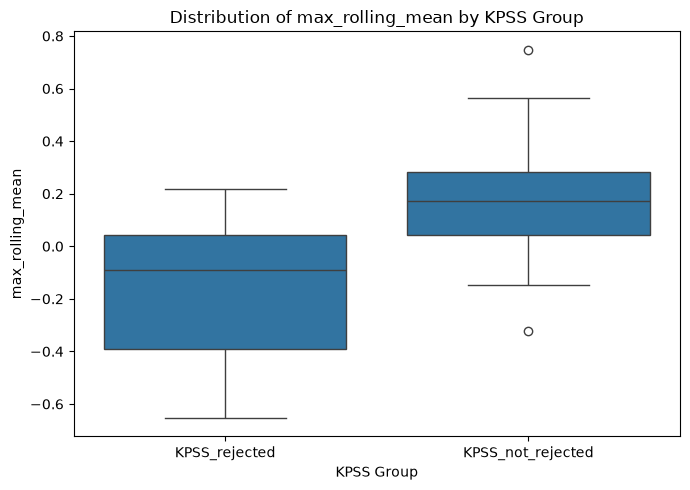

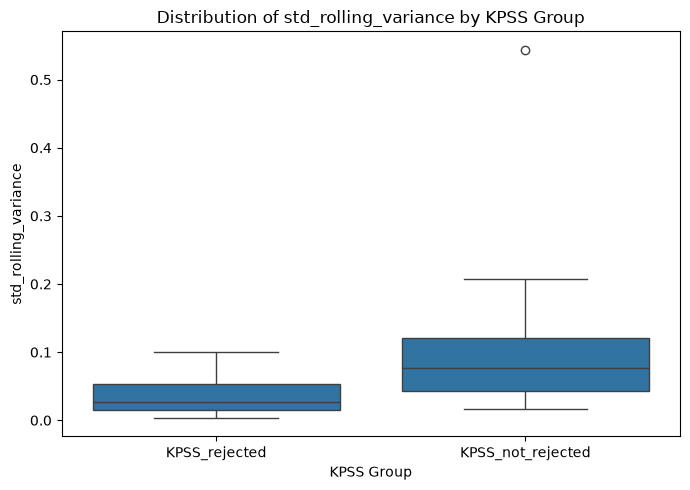

In [47]:
significant_features = [
    "max_rolling_variance",
    "max_rolling_mean",
    "std_rolling_variance"
]

import matplotlib.pyplot as plt
import seaborn as sns

for feature in significant_features:

    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=diagnostic_features_df,
        x="KPSS_group",
        y=feature,
        order=["KPSS_rejected", "KPSS_not_rejected"]
    )

    plt.title(f"Distribution of {feature} by KPSS Group")
    plt.xlabel("KPSS Group")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

### Interpretation of Boxplots

The boxplots illustrate the distributional differences between the two KPSS groups for the three features that remained statistically significant after FDR correction.

**1. Maximum Rolling Variance**

The KPSS_not_rejected group shows a higher median and a wider interquartile range than the KPSS_rejected group. This indicates higher maximum rolling variance and greater variation across recordings in this group.

**2. Maximum Rolling Mean**

The KPSS_rejected group has a negative median, whereas the KPSS_not_rejected group has a positive median. The distributions show a noticeable difference, although some observations in the KPSS_not_rejected group appear as outliers.

**3. Standard Deviation of Rolling Variance**

The KPSS_not_rejected group has a higher median and a wider distribution. A high-value outlier is also visible in this group.

Overall, the visualizations support the statistical findings that these three rolling features differ between the KPSS groups. In particular, the KPSS_not_rejected group tends to show higher values for all three features.

These visual observations are consistent with the Mann–Whitney U tests and the Benjamini–Hochberg FDR results. However, the boxplots alone do not establish the underlying physiological reasons for these differences.

### 8.10 Outlier Detection Using the IQR Method

The boxplots showed potential outliers, particularly in the KPSS_not_rejected group.

In this step, we use the Interquartile Range (IQR) method to identify potential outliers in the three statistically significant features.

The IQR is calculated as:

\[
IQR = Q_3 - Q_1
\]

The lower and upper boundaries are:

\[
Lower = Q_1 - 1.5 \times IQR
\]

\[
Upper = Q_3 + 1.5 \times IQR
\]

Observations outside these boundaries are flagged as potential outliers.

This analysis is intended to identify unusual observations, not automatically remove them.

In [51]:
outlier_results = []

for feature in significant_features:

    for group in ["KPSS_rejected", "KPSS_not_rejected"]:

        values = diagnostic_features_df.loc[
            diagnostic_features_df["KPSS_group"] == group,
            feature
        ].dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = values[
            (values < lower_bound) | (values > upper_bound)
        ]

        outlier_results.append({
            "Feature": feature,
            "KPSS_group": group,
            "Lower_bound": lower_bound,
            "Upper_bound": upper_bound,
            "Outlier_count": len(outliers),
            "Outlier_values": outliers.tolist()
        })

outlier_results_df = pd.DataFrame(outlier_results)

display(outlier_results_df.round(5))

,Feature,KPSS_group,Lower_bound,Upper_bound,Outlier_count,Outlier_values
0,max_rolling_variance,KPSS_rejected,-0.48397,1.21043,0,[]
1,max_rolling_variance,KPSS_not_rejected,-0.68267,2.64555,1,[6.179993]
2,max_rolling_mean,KPSS_rejected,-1.04336,0.69676,0,[]
3,max_rolling_mean,KPSS_not_rejected,-0.31915,0.64326,2,"[0.747679, -0.324154]"
4,std_rolling_variance,KPSS_rejected,-0.04315,0.11120,0,[]
5,std_rolling_variance,KPSS_not_rejected,-0.07221,0.23693,1,[0.543866]


### Interpretation of Outlier Detection

The IQR method identified four potential outlier observations across the three significant rolling features.

All detected outliers belonged to the KPSS_not_rejected group:

- Maximum rolling variance: 6.179993
- Maximum rolling mean: 0.747679 and -0.324154
- Standard deviation of rolling variance: 0.543866

No potential outliers were detected in the KPSS_rejected group.

The maximum rolling variance and standard deviation of rolling variance contained particularly high observations relative to their respective group distributions. The lower outlier in maximum rolling mean was only slightly outside the IQR boundary.

These observations require further investigation. They will not be removed automatically because extreme values may represent genuine signal characteristics rather than measurement or processing errors.

### 8.11 Sensitivity Analysis After Excluding Potential Outliers

The previous analysis identified four potential outliers using the IQR method.

In this step, we repeat the Mann–Whitney U tests for the three features that remained significant after FDR correction:

1. Maximum rolling variance
2. Maximum rolling mean
3. Standard deviation of rolling variance

Potential outliers will be temporarily excluded from their respective feature and KPSS group using the 1.5 × IQR rule.

The resulting p-values and effect sizes will be compared with the original results to evaluate the robustness of the findings.

No observations will be permanently removed from the original dataset.

In [55]:
sensitivity_results = []

for feature in significant_features:

    cleaned_groups = {}

    for group in ["KPSS_rejected", "KPSS_not_rejected"]:

        values = diagnostic_features_df.loc[
            diagnostic_features_df["KPSS_group"] == group,
            feature
        ].dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        cleaned_values = values[
            (values >= lower_bound) &
            (values <= upper_bound)
        ]

        cleaned_groups[group] = cleaned_values

    group1 = cleaned_groups["KPSS_rejected"]
    group2 = cleaned_groups["KPSS_not_rejected"]

    u_statistic, p_value = mannwhitneyu(
        group1,
        group2,
        alternative="two-sided",
        method="auto"
    )

    rank_biserial = (
        (2 * u_statistic) / (len(group1) * len(group2))
    ) - 1

    sensitivity_results.append({
        "Feature": feature,
        "N_rejected_after": len(group1),
        "N_not_rejected_after": len(group2),
        "U_statistic": u_statistic,
        "p_value_after": p_value,
        "Rank_biserial_after": rank_biserial
    })

sensitivity_results_df = pd.DataFrame(sensitivity_results)

display(sensitivity_results_df.round(5))

,Feature,N_rejected_after,N_not_rejected_after,U_statistic,p_value_after,Rank_biserial_after
0,max_rolling_variance,19,28,88.0,0.00012,-0.66917
1,max_rolling_mean,19,27,79.0,0.00008,-0.69201
2,std_rolling_variance,19,28,103.0,0.00043,-0.61278


### Interpretation of Sensitivity Analysis

The sensitivity analysis showed that all three features remained statistically significant after temporarily excluding potential outliers.

The p-values after outlier exclusion were:

- Maximum rolling variance: p = 0.00012
- Maximum rolling mean: p = 0.00008
- Standard deviation of rolling variance: p = 0.00043

The rank-biserial effect sizes also remained similar to the original results:

- Maximum rolling variance: -0.669
- Maximum rolling mean: -0.692
- Standard deviation of rolling variance: -0.613

The direction and magnitude of the group differences were therefore broadly consistent before and after outlier exclusion.

These findings suggest that the observed differences are not primarily driven by the identified extreme observations. The three features demonstrate preliminary robustness to this outlier-exclusion procedure.

### 8.12 Benjamini–Hochberg Correction for Sensitivity Analysis

To account for multiple comparisons in the sensitivity analysis, the Benjamini–Hochberg procedure is applied to the three Mann–Whitney U test p-values obtained after excluding potential outliers.

The adjusted p-values are evaluated using an FDR threshold of 0.05.

This provides a consistent statistical criterion for evaluating the robustness of the three significant features.

In [59]:
from statsmodels.stats.multitest import multipletests

reject_sensitivity, adjusted_p_sensitivity, _, _ = multipletests(
    sensitivity_results_df["p_value_after"],
    alpha=0.05,
    method="fdr_bh"
)

sensitivity_results_df["adjusted_p_value"] = adjusted_p_sensitivity
sensitivity_results_df["significant_FDR"] = reject_sensitivity

display(sensitivity_results_df.round(5))

print(
    "\nSignificant features after sensitivity FDR correction:",
    reject_sensitivity.sum(),
    "out of",
    len(reject_sensitivity)
)

,Feature,N_rejected_after,N_not_rejected_after,U_statistic,p_value_after,Rank_biserial_after,adjusted_p_value,significant_FDR
0,max_rolling_variance,19,28,88.0,0.00012,-0.66917,0.00018,True
1,max_rolling_mean,19,27,79.0,0.00008,-0.69201,0.00018,True
2,std_rolling_variance,19,28,103.0,0.00043,-0.61278,0.00043,True



Significant features after sensitivity FDR correction: 3 out of 3


### Interpretation of Sensitivity FDR Correction

After applying Benjamini–Hochberg correction to the sensitivity analysis, all three features remained statistically significant at an FDR threshold of 0.05.

The adjusted p-values were:

- Maximum rolling variance: 0.00018
- Maximum rolling mean: 0.00018
- Standard deviation of rolling variance: 0.00043

The rank-biserial effect sizes also remained relatively strong:

- Maximum rolling variance: -0.669
- Maximum rolling mean: -0.692
- Standard deviation of rolling variance: -0.613

These results indicate that the three group differences remain statistically significant after excluding the potential outliers and correcting for multiple comparisons.

The consistency between the original and sensitivity analyses provides evidence that these findings are not primarily driven by the identified outlier observations.

However, this sensitivity analysis only evaluates robustness to the specific IQR-based exclusion procedure. Further validation using independent ECG recordings will be necessary to establish generalizability.

### 8.13 Comparison of Original and Sensitivity Analysis Results

In this step, we compare the original Mann–Whitney U test results with the sensitivity analysis results.

The comparison includes:

- Original p-values and FDR-adjusted p-values.
- Original rank-biserial effect sizes.
- P-values and adjusted p-values after outlier exclusion.
- Effect sizes after outlier exclusion.

This comparison provides a consolidated assessment of the robustness of the three significant features.

In [65]:
comparison_df = mannwhitney_results_df[
    mannwhitney_results_df["Feature"].isin(significant_features)
][
    ["Feature", "p_value", "adjusted_p_value",
     "Rank_biserial", "significant_FDR"]
].merge(
    sensitivity_results_df[
        ["Feature", "p_value_after", "adjusted_p_value",
         "Rank_biserial_after", "significant_FDR"]
    ],
    on="Feature",
    suffixes=("_original", "_sensitivity")
)

display(comparison_df.round(5))

,Feature,p_value,adjusted_p_value_original,Rank_biserial,significant_FDR_original,p_value_after,adjusted_p_value_sensitivity,Rank_biserial_after,significant_FDR_sensitivity
0,std_rolling_variance,0.00029,0.00086,-0.62613,True,0.00043,0.00043,-0.61278,True
1,max_rolling_variance,0.00008,0.00051,-0.68058,True,0.00012,0.00018,-0.66917,True
2,max_rolling_mean,0.00011,0.00051,-0.66606,True,0.00008,0.00018,-0.69201,True


### 8.14 Final Summary of Statistically Significant Features

In this step, we consolidate the main findings for the three features that remained statistically significant after Benjamini–Hochberg FDR correction.

The table includes:

- Median values for both KPSS groups.
- Original Mann–Whitney U test results.
- Original FDR-adjusted p-values.
- Original rank-biserial effect sizes.
- Sensitivity analysis results after IQR-based outlier exclusion.

This table provides a compact overview of the features identified during Day 2.

In [68]:
# Select the three features significant after original FDR correction
final_features = [
    "std_rolling_variance",
    "max_rolling_variance",
    "max_rolling_mean"
]

# Calculate group medians
group_medians = (
    diagnostic_features_df
    .groupby("KPSS_group")[final_features]
    .median()
    .T
    .reset_index()
)

group_medians.columns = [
    "Feature",
    "Median_KPSS_rejected",
    "Median_KPSS_not_rejected"
]

# Merge original statistical results
final_results_df = group_medians.merge(
    mannwhitney_results_df[
        mannwhitney_results_df["Feature"].isin(final_features)
    ][
        ["Feature", "U_statistic", "p_value",
         "adjusted_p_value", "Rank_biserial", "significant_FDR"]
    ],
    on="Feature"
)

# Merge sensitivity analysis results
final_results_df = final_results_df.merge(
    sensitivity_results_df[
        sensitivity_results_df["Feature"].isin(final_features)
    ][
        ["Feature", "p_value_after", "adjusted_p_value",
         "Rank_biserial_after", "significant_FDR"]
    ],
    on="Feature",
    suffixes=("_original", "_sensitivity")
)

display(final_results_df.round(5))

,Feature,Median_KPSS_rejected,Median_KPSS_not_rejected,U_statistic,p_value,adjusted_p_value_original,Rank_biserial,significant_FDR_original,p_value_after,adjusted_p_value_sensitivity,Rank_biserial_after,significant_FDR_sensitivity
0,std_rolling_variance,0.07667,0.02714,103.0,0.00029,0.00086,-0.62613,True,0.00043,0.00043,-0.61278,True
1,max_rolling_variance,0.96673,0.30316,88.0,0.00008,0.00051,-0.68058,True,0.00012,0.00018,-0.66917,True
2,max_rolling_mean,0.17242,-0.09118,92.0,0.00011,0.00051,-0.66606,True,0.00008,0.00018,-0.69201,True


### 8.15 Validation of the Final Results Table

Before finalising the statistical analysis, we need to check whether all three significant features have complete statistical results.

The max_rolling_mean row contains missing values in the final table. We will inspect the original and sensitivity result tables to identify the reason.

This is a data validation step and does not involve repeating the statistical tests.

In [71]:
print("Original Mann–Whitney results:")
display(
    mannwhitney_results_df[
        mannwhitney_results_df["Feature"].isin(final_features)
    ]
)

print("\nSensitivity analysis results:")
display(
    sensitivity_results_df[
        sensitivity_results_df["Feature"].isin(final_features)
    ]
)

print("\nMissing values in final table:")
display(final_results_df.isnull().sum())

Original Mann–Whitney results:


,Feature,U_statistic,p_value,Rank_biserial,adjusted_p_value,significant_FDR
2,std_rolling_variance,103.0,0.000288,-0.626134,0.000863,True
3,max_rolling_variance,88.0,0.000081,-0.680581,0.000514,True
8,max_rolling_mean,92.0,0.000114,-0.666062,0.000514,True



Sensitivity analysis results:


,Feature,N_rejected_after,N_not_rejected_after,U_statistic,p_value_after,Rank_biserial_after,adjusted_p_value,significant_FDR
0,max_rolling_variance,19,28,88.0,0.000119,-0.669173,0.000179,True
1,max_rolling_mean,19,27,79.0,0.000079,-0.692008,0.000179,True
2,std_rolling_variance,19,28,103.0,0.000427,-0.612782,0.000427,True



Missing values in final table:


Feature                         0
Median_KPSS_rejected            0
Median_KPSS_not_rejected        0
U_statistic                     0
p_value                         0
adjusted_p_value_original       0
Rank_biserial                   0
significant_FDR_original        0
p_value_after                   0
adjusted_p_value_sensitivity    0
Rank_biserial_after             0
significant_FDR_sensitivity     0
dtype: int64

In [73]:
# Correct the final results table using the original result tables

original_results = mannwhitney_results_df[
    mannwhitney_results_df["Feature"].isin(final_features)
].copy()

sensitivity_results = sensitivity_results_df[
    sensitivity_results_df["Feature"].isin(final_features)
].copy()

# Check the feature names before merging
print("Original features:")
print(original_results["Feature"].tolist())

print("\nSensitivity features:")
print(sensitivity_results["Feature"].tolist())

# Merge using the feature name
corrected_final_results = (
    group_medians
    .merge(
        original_results[
            ["Feature", "U_statistic", "p_value",
             "adjusted_p_value", "Rank_biserial",
             "significant_FDR"]
        ],
        on="Feature",
        how="inner"
    )
    .merge(
        sensitivity_results[
            ["Feature", "p_value_after",
             "adjusted_p_value", "Rank_biserial_after",
             "significant_FDR"]
        ],
        on="Feature",
        how="inner",
        suffixes=("_original", "_sensitivity")
    )
)

display(corrected_final_results.round(5))

print("\nMissing values:")
print(corrected_final_results.isnull().sum())

Original features:
['std_rolling_variance', 'max_rolling_variance', 'max_rolling_mean']

Sensitivity features:
['max_rolling_variance', 'max_rolling_mean', 'std_rolling_variance']


,Feature,Median_KPSS_rejected,Median_KPSS_not_rejected,U_statistic,p_value,adjusted_p_value_original,Rank_biserial,significant_FDR_original,p_value_after,adjusted_p_value_sensitivity,Rank_biserial_after,significant_FDR_sensitivity
0,std_rolling_variance,0.07667,0.02714,103.0,0.00029,0.00086,-0.62613,True,0.00043,0.00043,-0.61278,True
1,max_rolling_variance,0.96673,0.30316,88.0,0.00008,0.00051,-0.68058,True,0.00012,0.00018,-0.66917,True
2,max_rolling_mean,0.17242,-0.09118,92.0,0.00011,0.00051,-0.66606,True,0.00008,0.00018,-0.69201,True



Missing values:
Feature                         0
Median_KPSS_rejected            0
Median_KPSS_not_rejected        0
U_statistic                     0
p_value                         0
adjusted_p_value_original       0
Rank_biserial                   0
significant_FDR_original        0
p_value_after                   0
adjusted_p_value_sensitivity    0
Rank_biserial_after             0
significant_FDR_sensitivity     0
dtype: int64


### 8.17 Final Interpretation of Day 2 Statistical Analysis

The final statistical analysis identified three features that showed
significant differences between the two KPSS groups after
Benjamini–Hochberg FDR correction:

1. std_rolling_variance
2. max_rolling_variance
3. max_rolling_mean

All three features remained significant after the IQR-based
sensitivity analysis and its corresponding FDR correction.

The final results table contained no missing values.

The median comparisons showed different group patterns across
the three features. Therefore, the direction of each group difference
must be interpreted using the observed distributions and verified
effect-size orientation.

These findings are exploratory and do not establish clinical
significance or causality.



### 8.17 Verification of Rank-Biserial Effect Size Direction

Before interpreting the direction of the effect sizes, we verify the
ordering of the two groups used in the Mann–Whitney U test.

We explicitly define:
- Group 1: KPSS_rejected
- Group 2: KPSS_not_rejected

We recalculate the U statistic and rank-biserial correlation, then
compare the group medians and mean ranks.

This is a validation step. It does not change the statistical
significance conclusions.

In [77]:
from scipy.stats import mannwhitneyu, rankdata
import numpy as np
import pandas as pd

direction_check = []

for feature in final_features:

    g1 = diagnostic_features_df.loc[
        diagnostic_features_df["KPSS_group"] == "KPSS_rejected",
        feature
    ].dropna().to_numpy()

    g2 = diagnostic_features_df.loc[
        diagnostic_features_df["KPSS_group"] == "KPSS_not_rejected",
        feature
    ].dropna().to_numpy()

    result = mannwhitneyu(
        g1, g2,
        alternative="two-sided",
        method="auto"
    )

    rank_biserial = (
        2 * result.statistic / (len(g1) * len(g2))
    ) - 1

    combined = np.concatenate([g1, g2])
    all_ranks = rankdata(combined)

    direction_check.append({
        "Feature": feature,
        "n_rejected": len(g1),
        "n_not_rejected": len(g2),
        "Median_rejected": np.median(g1),
        "Median_not_rejected": np.median(g2),
        "Mean_rank_rejected": all_ranks[:len(g1)].mean(),
        "Mean_rank_not_rejected": all_ranks[len(g1):].mean(),
        "U_rejected_first": result.statistic,
        "Rank_biserial_recalculated": rank_biserial
    })

direction_check_df = pd.DataFrame(direction_check)

display(direction_check_df.round(5))

,Feature,n_rejected,n_not_rejected,Median_rejected,Median_not_rejected,Mean_rank_rejected,Mean_rank_not_rejected,U_rejected_first,Rank_biserial_recalculated
0,std_rolling_variance,19,29,0.02714,0.07667,15.42105,30.44828,103.0,-0.62613
1,max_rolling_variance,19,29,0.30316,0.96673,14.63158,30.96552,88.0,-0.68058
2,max_rolling_mean,19,29,-0.09118,0.17242,14.84211,30.82759,92.0,-0.66606


### Interpretation of Rank-Biserial Effect Direction

The verification confirmed that the rank-biserial effect sizes are
consistent with the group medians and mean ranks.

For all three statistically significant features, the KPSS_rejected
group showed lower median values and lower mean ranks than the
KPSS_not_rejected group.

The rank-biserial correlations were:

- std_rolling_variance: -0.62613
- max_rolling_variance: -0.68058
- max_rolling_mean: -0.66606

The negative values indicate that observations in the KPSS_rejected
group generally had lower ranks than observations in the
KPSS_not_rejected group.

All three features showed substantial group differences. These
results describe associations between the rolling features and
KPSS-based group classification; they do not establish causation.

## 8.18 Overall Summary of Day 2 Statistical Analysis

### 1. Correlation Analysis

Spearman correlation analysis was performed to examine relationships
among the numerical features. Several strong correlations were found,
including correlations between mean and median rolling statistics.

Pairwise significance testing with Benjamini–Hochberg correction
identified 33 significant relationships among 66 pairwise tests.

### 2. KPSS Group Comparisons

The recordings were divided into two groups:
- KPSS_rejected: 19 recordings
- KPSS_not_rejected: 29 recordings

Mann–Whitney U tests were performed to compare nine rolling features.

After Benjamini–Hochberg correction, three features remained
statistically significant:

- std_rolling_variance
- max_rolling_variance
- max_rolling_mean

### 3. Effect Size Analysis

Rank-biserial correlations were calculated to assess the magnitude
and direction of the group differences.

All three significant features showed negative rank-biserial
correlations, indicating lower ranks in the KPSS_rejected group.

### 4. Outlier and Sensitivity Analysis

The IQR method identified four potential outlier observations
across the three significant features.

Sensitivity analysis was conducted after excluding these observations
from their respective feature-group comparisons.

All three features remained statistically significant after
Benjamini–Hochberg correction.

The effect sizes also remained similar to the original results.

### 5. Overall Conclusion

The statistical analysis identified three rolling features that
showed robust differences between recordings classified according
to the KPSS test.

These findings provide an initial statistical basis for further
investigation of signal variability and temporal behaviour in the
MIT-BIH dataset.

No observations were permanently removed, and no causal conclusions
were drawn from these statistical comparisons.